# Spaceship Titanic

## Dataset Description

In this competition your task is to predict whether a passenger was transported to an alternate dimension during the Spaceship Titanic's collision with the spacetime anomaly. To help you make these predictions, you're given a set of personal records recovered from the ship's damaged computer system.

https://www.kaggle.com/competitions/spaceship-titanic/data

## Data Field Descriptions

- `PassengerId` - A unique Id for each passenger. Each Id takes the form `gggg_pp` where `gggg` indicates a group the passenger is travelling with and `pp` is their number within the group. People in a group are often family members, but not always.
- `HomePlanet` - The planet the passenger departed from, typically their planet of permanent residence.
- `CryoSleep` - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
- `Cabin` - The cabin number where the passenger is staying. Takes the form `deck/num/side`, where side can be either `P` for Port or `S` for Starboard.
- `Destination` - The planet the passenger will be debarking to.
- `Age` - The age of the passenger.
- `VIP` - Whether the passenger has paid for special VIP service during the voyage.
- `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
- `Name` - The first and last names of the passenger.
- `Transported` - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.

## Data Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from typing import Any


pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../data/train.csv")

In [3]:
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


In [4]:
df.dtypes

PassengerId         str
HomePlanet          str
CryoSleep        object
Cabin               str
Destination         str
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name                str
Transported        bool
dtype: object

In [5]:
df.describe(include=["number"])

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [6]:
df.describe(include=["str", "object", "bool"])

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name,Transported
count,8693,8492,8476,8494,8511,8490,8493,8693
unique,8693,3,2,6560,3,2,8473,2
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Elaney Webstephrey,True
freq,1,4602,5439,8,5915,8291,2,4378


Let's investigate why the data contains several people with the same name.

In [7]:
df[df['Name'].duplicated(keep=False)].dropna(subset="Name").sort_values(["Name"])

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7270,7775_01,Europa,False,C/253/P,55 Cancri e,28.0,False,7.0,489.0,0.0,4.0,6027.0,Alraium Disivering,False
6296,6665_01,Europa,True,B/222/P,55 Cancri e,17.0,False,0.0,0.0,0.0,0.0,0.0,Alraium Disivering,True
476,0512_02,Europa,True,D/18/S,TRAPPIST-1e,55.0,False,0.0,0.0,0.0,0.0,0.0,Ankalik Nateansive,True
2930,3176_01,Europa,False,E/196/P,TRAPPIST-1e,77.0,False,0.0,9032.0,0.0,128.0,1464.0,Ankalik Nateansive,True
8488,9071_01,Earth,False,F/1855/P,55 Cancri e,22.0,False,0.0,0.0,1072.0,46.0,3.0,Anton Woody,False
2991,3236_03,Earth,False,E/200/P,TRAPPIST-1e,18.0,False,0.0,30.0,0.0,756.0,5.0,Anton Woody,False
2559,2746_01,Mars,False,F/569/P,TRAPPIST-1e,52.0,False,758.0,0.0,356.0,5.0,0.0,Apix Wala,False
4108,4387_01,Mars,False,F/902/P,PSO J318.5-22,32.0,False,192.0,0.0,441.0,18.0,0.0,Apix Wala,False
7871,8398_01,Europa,True,B/329/S,TRAPPIST-1e,15.0,False,0.0,0.0,0.0,0.0,0.0,Asch Stradick,True
6086,6432_01,Europa,False,D/202/P,55 Cancri e,55.0,False,114.0,222.0,0.0,2575.0,2919.0,Asch Stradick,False


We have a few duplicate names, but they all seem to be different people, so I'm gonna keep them.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [9]:
df.loc[df.duplicated()]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported


In [10]:
df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

## Data Preparation

### Feature Creation

In [11]:
cabin_splitted = df["Cabin"].str.split("/", expand=True)
df["Cabin_Deck"] = cabin_splitted[0]
df["Cabin_Num"] = cabin_splitted[1]
df["Cabin_Side"] = cabin_splitted[2]
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S


In [12]:
df["Cabin_Group_Size"] = df["Cabin"].map(df["Cabin"].value_counts())
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,1.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,1.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,2.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,2.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,1.0


In [13]:
passenger_id_splitted = df["PassengerId"].str.split("_", expand=True)
df["Passenger_Group_ID"] = passenger_id_splitted[0]
df["Passenger_Group_Position"] = passenger_id_splitted[1]
df["Travel_Group_Size"] = df["Passenger_Group_ID"].map(df["Passenger_Group_ID"].value_counts())
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size,Passenger_Group_ID,Passenger_Group_Position,Travel_Group_Size
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,1.0,0001,01,1
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,1.0,0002,01,1
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,2.0,0003,01,2
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,2.0,0003,02,2
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,1.0,0004,01,1


### Dropping Irrelevant Columns

In [14]:
df = df.drop(columns=["PassengerId", "Cabin", "Name"])
df.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size,Passenger_Group_ID,Passenger_Group_Position,Travel_Group_Size
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,0,P,1.0,0001,01,1
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,0,S,1.0,0002,01,1
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,0,S,2.0,0003,01,2
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,0,S,2.0,0003,02,2
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,1,S,1.0,0004,01,1


### Renaming Columns and Changing Data Types

In [15]:
df = df.rename(columns={
    "HomePlanet": "Home_Planet",
    "CryoSleep": "Cryo_Sleep",
    "RoomService": "Room_Service",
    "FoodCourt": "Food_Court",
    "ShoppingMall": "Shopping_Mall",
    "VRDeck": "VR_Deck",
})

In [16]:
df = df[[
    "Home_Planet",
    "Destination",
    "Age",
    "Cryo_Sleep",
    "VIP",
    "Room_Service",
    "Food_Court",
    "Shopping_Mall",
    "Spa",
    "VR_Deck",
    "Cabin_Deck",
    "Cabin_Num",
    "Cabin_Side",
    "Cabin_Group_Size",
    "Passenger_Group_ID",
    "Passenger_Group_Position",
    "Travel_Group_Size", 
    "Transported"
]]

In [17]:
df.head()

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size,Passenger_Group_ID,Passenger_Group_Position,Travel_Group_Size,Transported
0,Europa,TRAPPIST-1e,39.0,False,False,0.0,0.0,0.0,0.0,0.0,B,0,P,1.0,0001,01,1,False
1,Earth,TRAPPIST-1e,24.0,False,False,109.0,9.0,25.0,549.0,44.0,F,0,S,1.0,0002,01,1,True
2,Europa,TRAPPIST-1e,58.0,False,True,43.0,3576.0,0.0,6715.0,49.0,A,0,S,2.0,0003,01,2,False
3,Europa,TRAPPIST-1e,33.0,False,False,0.0,1283.0,371.0,3329.0,193.0,A,0,S,2.0,0003,02,2,False
4,Earth,TRAPPIST-1e,16.0,False,False,303.0,70.0,151.0,565.0,2.0,F,1,S,1.0,0004,01,1,True


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Home_Planet               8492 non-null   str    
 1   Destination               8511 non-null   str    
 2   Age                       8514 non-null   float64
 3   Cryo_Sleep                8476 non-null   object 
 4   VIP                       8490 non-null   object 
 5   Room_Service              8512 non-null   float64
 6   Food_Court                8510 non-null   float64
 7   Shopping_Mall             8485 non-null   float64
 8   Spa                       8510 non-null   float64
 9   VR_Deck                   8505 non-null   float64
 10  Cabin_Deck                8494 non-null   str    
 11  Cabin_Num                 8494 non-null   str    
 12  Cabin_Side                8494 non-null   str    
 13  Cabin_Group_Size          8494 non-null   float64
 14  Passenger_Group_ID 

In [19]:
df["Home_Planet"] = df["Home_Planet"].astype("category")
df["Destination"] = df["Destination"].astype("category")
df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("boolean")
df["VIP"] = df["VIP"].astype("boolean")
df["Cabin_Deck"] = df["Cabin_Deck"].astype("category")
df["Cabin_Num"] = df["Cabin_Num"].astype("Int64")
df["Cabin_Side"] = df["Cabin_Side"].astype("category")
df["Cabin_Group_Size"] = df["Cabin_Group_Size"].astype("Int64").astype("category")
df["Passenger_Group_ID"] = df["Passenger_Group_ID"].astype("Int64")
df["Passenger_Group_Position"] = df["Passenger_Group_Position"].astype("Int64").astype("category")
df["Travel_Group_Size"] = df["Travel_Group_Size"].astype("category")

In [20]:
df.describe(include=["category", "boolean"])

,Home_Planet,Destination,Cryo_Sleep,VIP,Cabin_Deck,Cabin_Side,Cabin_Group_Size,Passenger_Group_Position,Travel_Group_Size
count,8492,8511,8476,8490,8494,8494,8494,8693,8693
unique,3,3,2,2,8,2,8,8,8
top,Earth,TRAPPIST-1e,False,False,F,S,1,1,1
freq,4602,5915,5439,8291,2794,4288,5427,6217,4805


In [21]:
df.isna().sum()

Home_Planet                 201
Destination                 182
Age                         179
Cryo_Sleep                  217
VIP                         203
Room_Service                181
Food_Court                  183
Shopping_Mall               208
Spa                         183
VR_Deck                     188
Cabin_Deck                  199
Cabin_Num                   199
Cabin_Side                  199
Cabin_Group_Size            199
Passenger_Group_ID            0
Passenger_Group_Position      0
Travel_Group_Size             0
Transported                   0
dtype: int64

## Feature Understanding

### Univariate Analysis

#### Home Planet

In [22]:
df["Home_Planet"].value_counts(dropna=False)

Home_Planet
Earth     4602
Europa    2131
Mars      1759
NaN        201
Name: count, dtype: int64

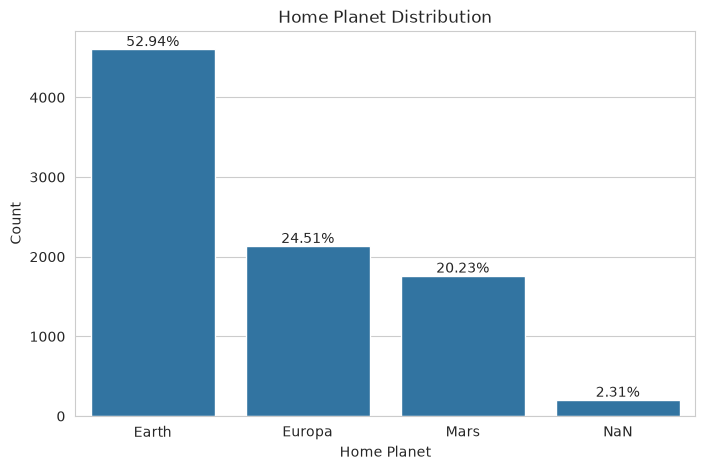

In [23]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Home_Planet"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Home_Planet"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Home Planet Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Home Planet")
plt.show()

#### Destination

In [24]:
df["Destination"].value_counts(dropna=False)

Destination
TRAPPIST-1e      5915
55 Cancri e      1800
PSO J318.5-22     796
NaN               182
Name: count, dtype: int64

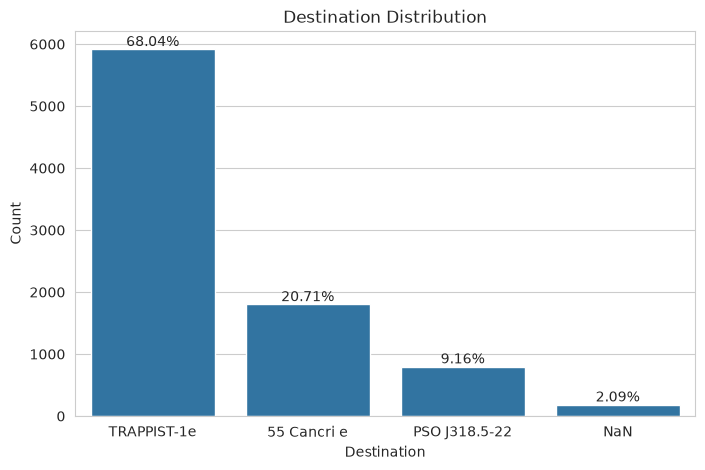

In [25]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Destination"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Destination"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Destination Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Destination")
plt.show()

#### Age

In [26]:
df["Age"].describe()

count    8514.000000
mean       28.827930
std        14.489021
min         0.000000
25%        19.000000
50%        27.000000
75%        38.000000
max        79.000000
Name: Age, dtype: float64

In [27]:
df["Age"].isna().sum()

np.int64(179)

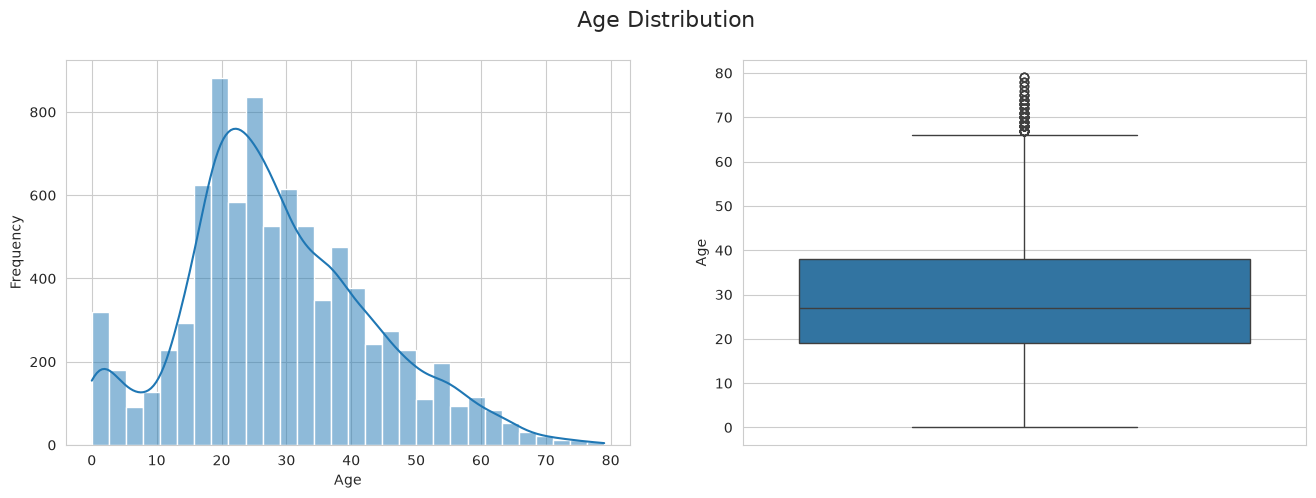

In [28]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Age Distribution", fontsize=16)

ax = sns.histplot(df["Age"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Age")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Age"], ax=axes[1])
ax.set_ylabel("Age")

plt.show()

#### Cryo Sleep

In [29]:
df["Cryo_Sleep"].value_counts(dropna=False)

Cryo_Sleep
False    5439
True     3037
<NA>      217
Name: count, dtype: Int64

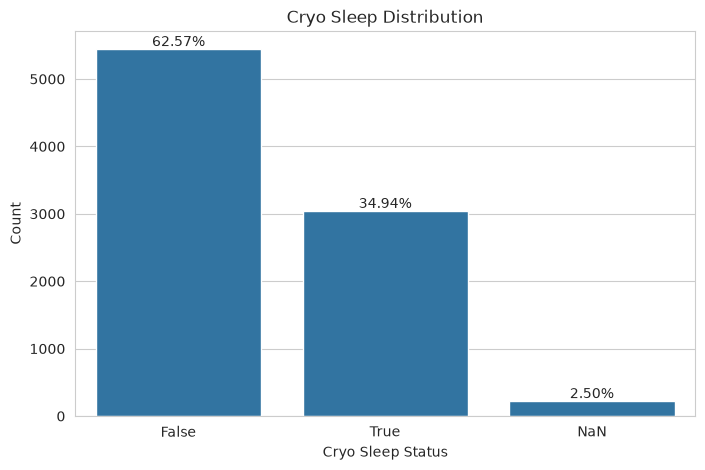

In [30]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cryo_Sleep"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cryo_Sleep"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cryo Sleep Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cryo Sleep Status")
plt.show()

#### VIP

In [31]:
df["VIP"].value_counts(dropna=False)

VIP
False    8291
<NA>      203
True      199
Name: count, dtype: Int64

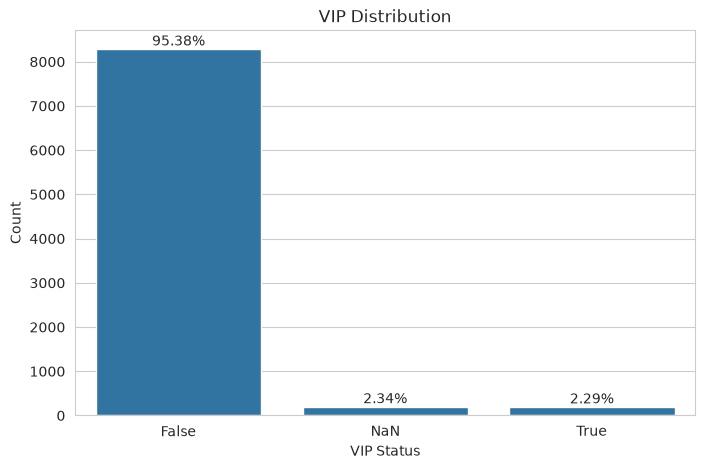

In [32]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["VIP"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["VIP"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("VIP Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("VIP Status")
plt.show()

#### Room Service

In [33]:
df["Room_Service"].describe()

count     8512.000000
mean       224.687617
std        666.717663
min          0.000000
25%          0.000000
50%          0.000000
75%         47.000000
max      14327.000000
Name: Room_Service, dtype: float64

In [34]:
df["Room_Service"].isna().sum()

np.int64(181)

In [35]:
df["Room_Service"].value_counts(dropna=False)

Room_Service
0.0       5577
NaN        181
1.0        117
2.0         79
3.0         61
          ... 
459.0        1
1003.0       1
1569.0       1
8586.0       1
745.0        1
Name: count, Length: 1274, dtype: int64

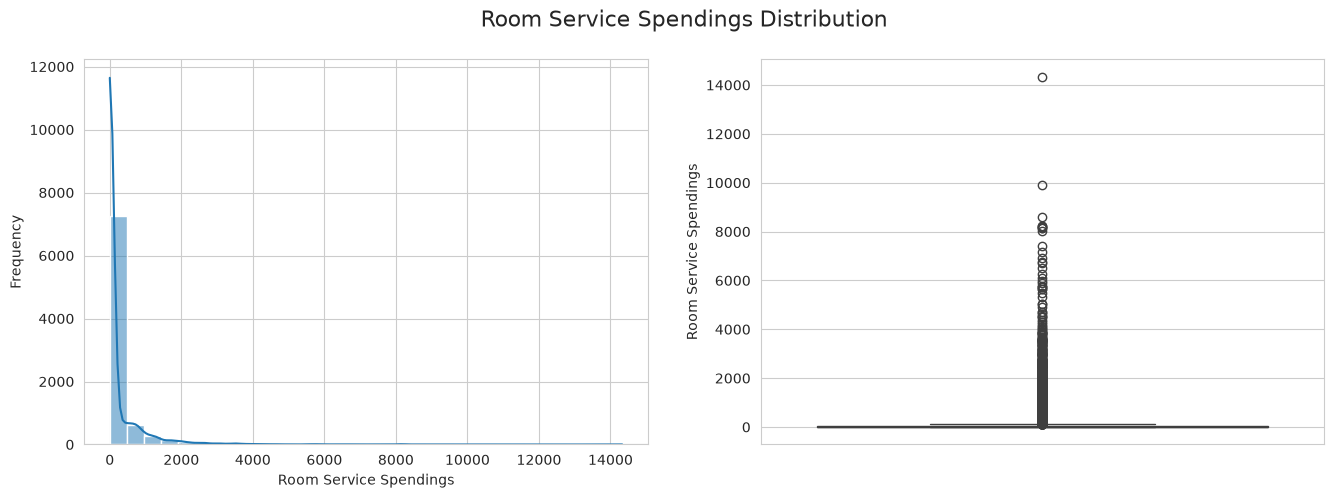

In [36]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Room Service Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Room_Service"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Room Service Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Room_Service"], ax=axes[1])
ax.set_ylabel("Room Service Spendings")

plt.show()

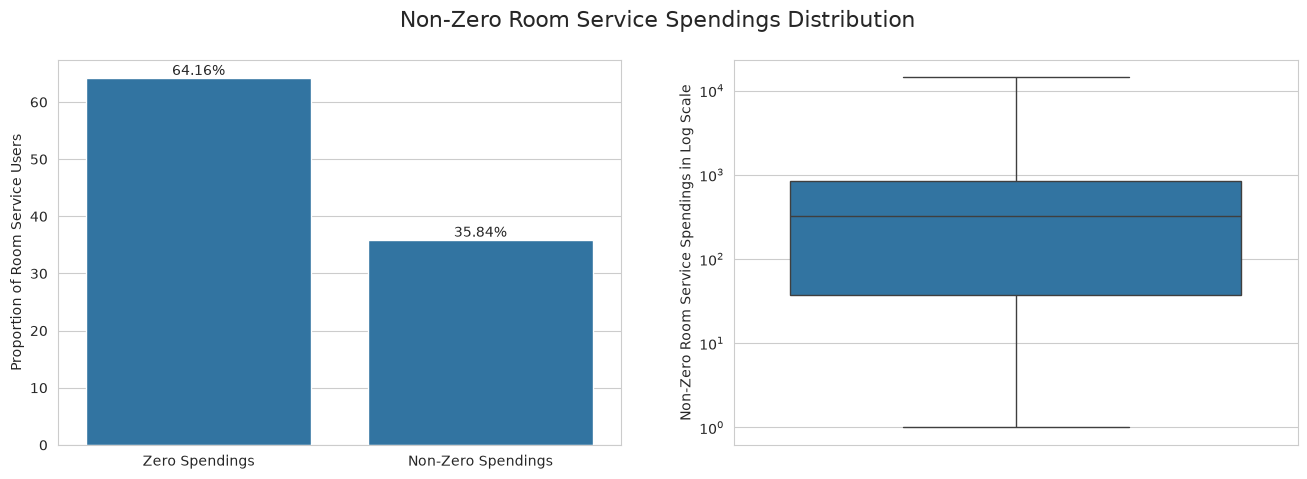

In [37]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Room Service Spendings Distribution", fontsize=16)

room_service_proportion = (df["Room_Service"] == 0).value_counts(normalize=True) * 100
room_service_proportion = room_service_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(room_service_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Room Service Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Room_Service > 0")["Room_Service"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Room Service Spendings in Log Scale")

plt.show()

#### Food Court

In [38]:
df["Food_Court"].describe()

count     8510.000000
mean       458.077203
std       1611.489240
min          0.000000
25%          0.000000
50%          0.000000
75%         76.000000
max      29813.000000
Name: Food_Court, dtype: float64

In [39]:
df["Food_Court"].isna().sum()

np.int64(183)

In [40]:
df["Food_Court"].value_counts(dropna=False)

Food_Court
0.0       5456
NaN        183
1.0        116
2.0         75
3.0         53
          ... 
1015.0       1
1146.0       1
3208.0       1
6819.0       1
4688.0       1
Name: count, Length: 1508, dtype: int64

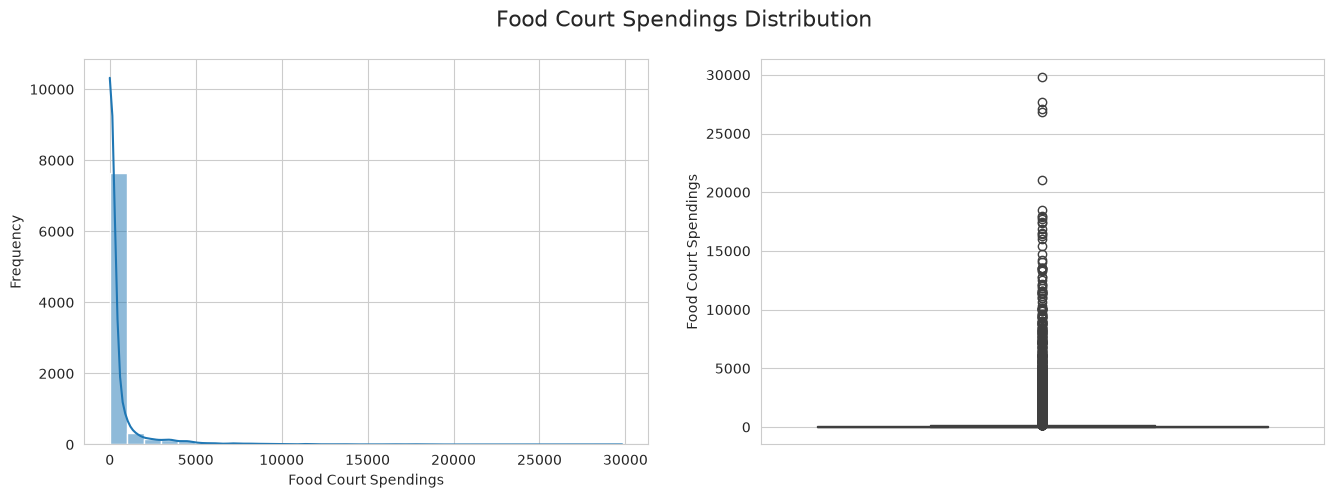

In [41]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Food Court Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Food_Court"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Food Court Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Food_Court"], ax=axes[1])
ax.set_ylabel("Food Court Spendings")

plt.show()

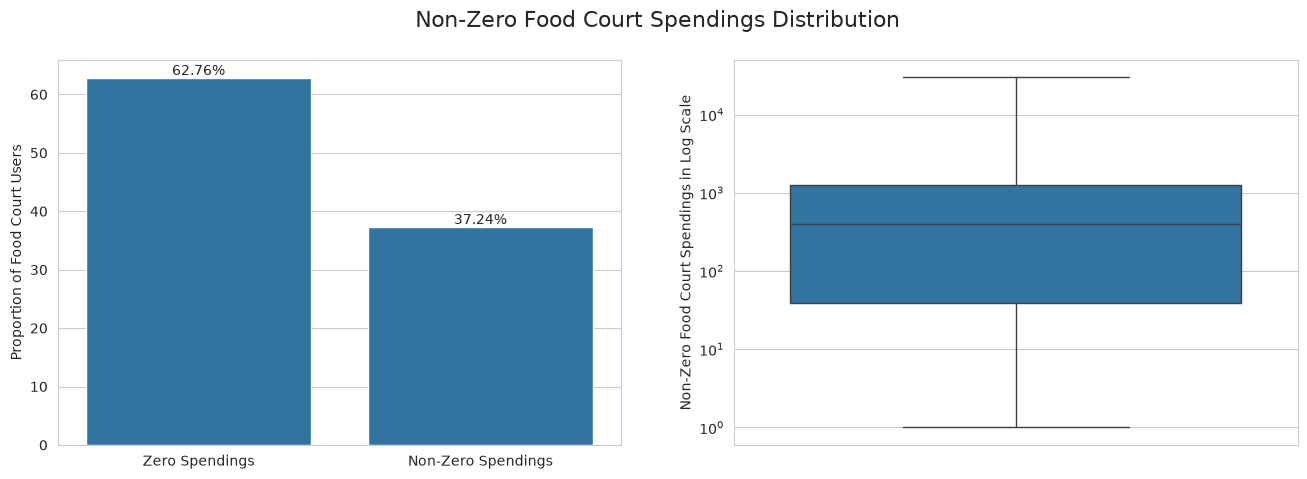

In [42]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Food Court Spendings Distribution", fontsize=16)

food_court_proportion = (df["Food_Court"] == 0).value_counts(normalize=True) * 100
food_court_proportion = food_court_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(food_court_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Food Court Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Food_Court > 0")["Food_Court"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Food Court Spendings in Log Scale")

plt.show()

#### Shopping Mall

In [43]:
df["Shopping_Mall"].describe()

count     8485.000000
mean       173.729169
std        604.696458
min          0.000000
25%          0.000000
50%          0.000000
75%         27.000000
max      23492.000000
Name: Shopping_Mall, dtype: float64

In [44]:
df["Shopping_Mall"].isna().sum()

np.int64(208)

In [45]:
df["Shopping_Mall"].value_counts(dropna=False)

Shopping_Mall
0.0       5587
NaN        208
1.0        153
2.0         80
3.0         59
          ... 
918.0        1
205.0        1
1085.0       1
510.0        1
1872.0       1
Name: count, Length: 1116, dtype: int64

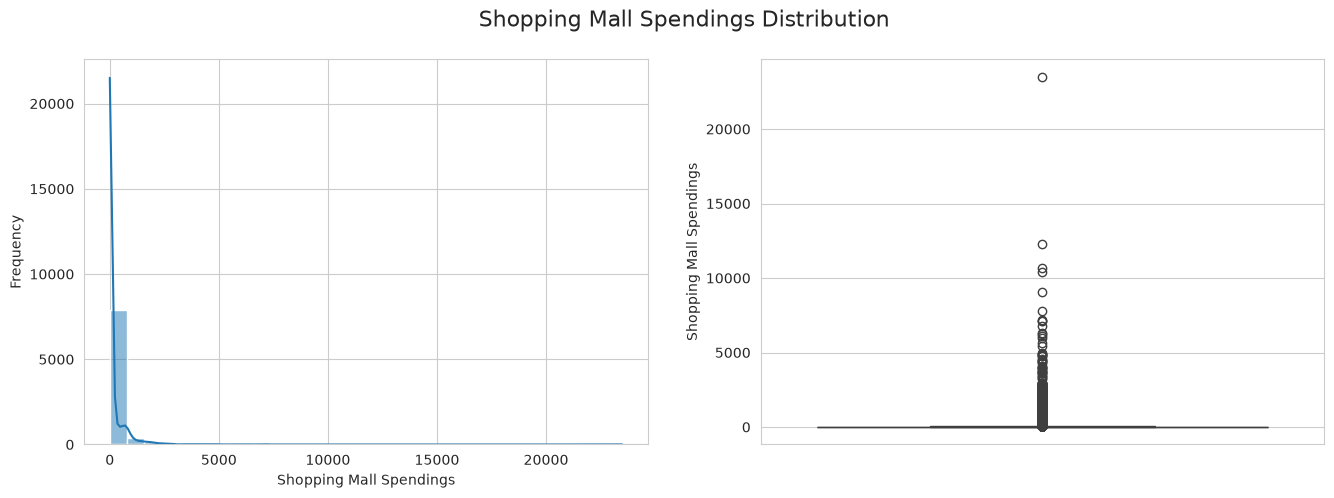

In [46]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Shopping Mall Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Shopping_Mall"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Shopping Mall Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Shopping_Mall"], ax=axes[1])
ax.set_ylabel("Shopping Mall Spendings")

plt.show()

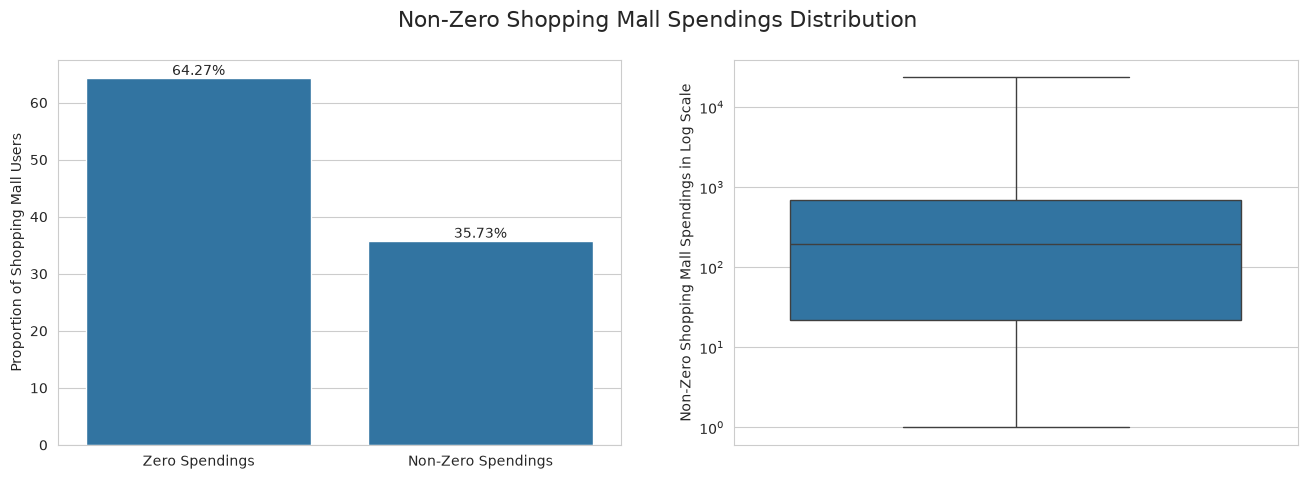

In [47]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Shopping Mall Spendings Distribution", fontsize=16)

shopping_mall_proportion = (df["Shopping_Mall"] == 0).value_counts(normalize=True) * 100
shopping_mall_proportion = shopping_mall_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(shopping_mall_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Shopping Mall Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Shopping_Mall > 0")["Shopping_Mall"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Shopping Mall Spendings in Log Scale")

plt.show()

#### Spa

In [48]:
df["Spa"].describe()

count     8510.000000
mean       311.138778
std       1136.705535
min          0.000000
25%          0.000000
50%          0.000000
75%         59.000000
max      22408.000000
Name: Spa, dtype: float64

In [49]:
df["Spa"].isna().sum()

np.int64(183)

In [50]:
df["Spa"].value_counts(dropna=False)

Spa
0.0       5324
NaN        183
1.0        146
2.0        105
3.0         53
          ... 
269.0        1
3238.0       1
2868.0       1
1107.0       1
1643.0       1
Name: count, Length: 1328, dtype: int64

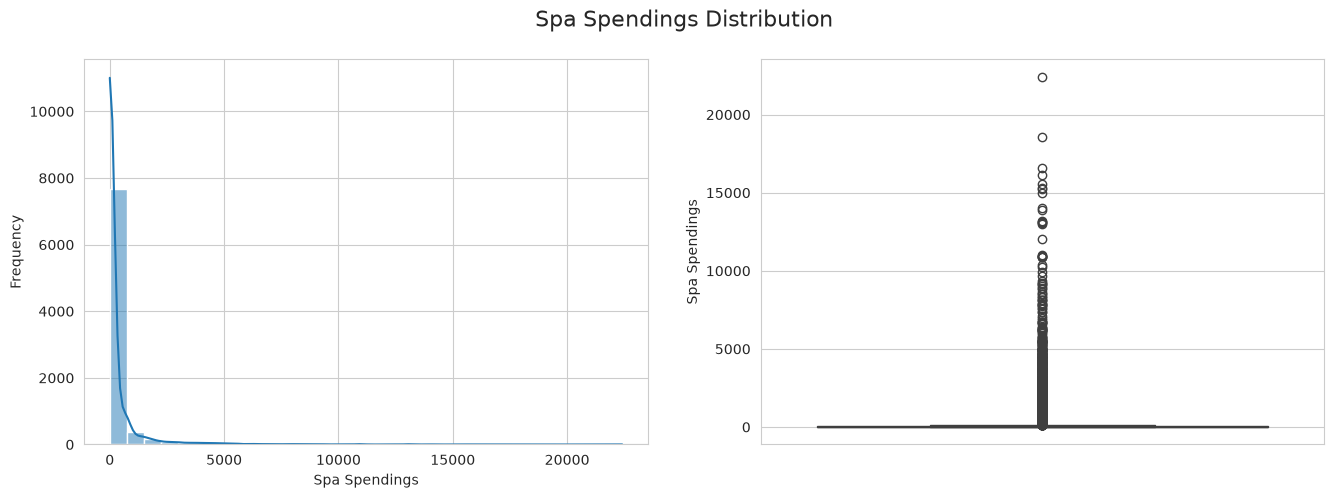

In [51]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Spa Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Spa"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Spa Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Spa"], ax=axes[1])
ax.set_ylabel("Spa Spendings")

plt.show()

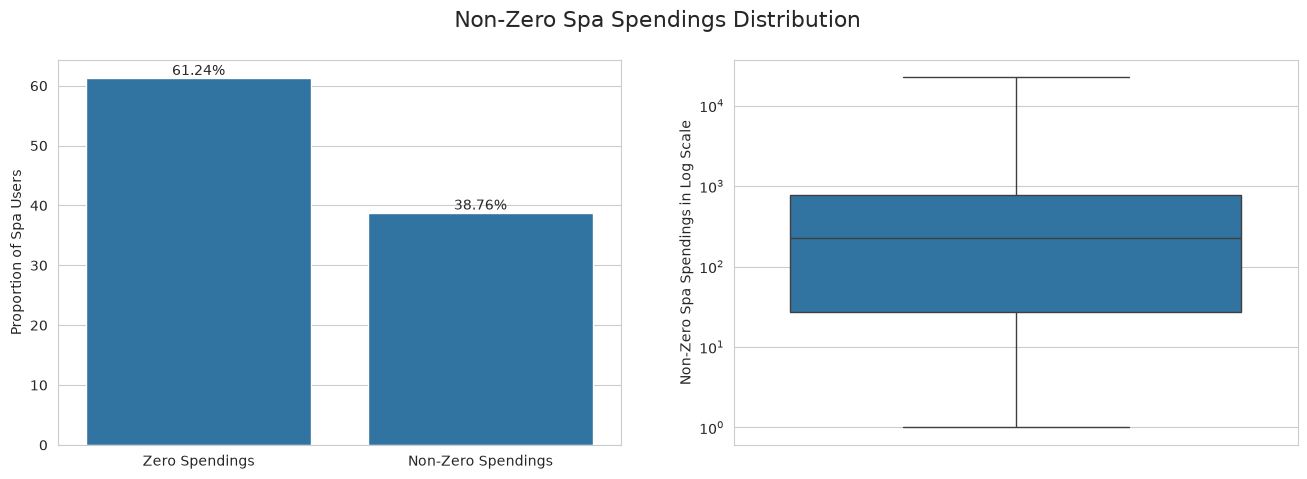

In [52]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Spa Spendings Distribution", fontsize=16)

spa_proportion = (df["Spa"] == 0).value_counts(normalize=True) * 100
spa_proportion = spa_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(spa_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Spa Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Spa > 0")["Spa"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Spa Spendings in Log Scale")

plt.show()

#### VR Deck

In [53]:
df["VR_Deck"].describe()

count     8505.000000
mean       304.854791
std       1145.717189
min          0.000000
25%          0.000000
50%          0.000000
75%         46.000000
max      24133.000000
Name: VR_Deck, dtype: float64

In [54]:
df["VR_Deck"].isna().sum()

np.int64(188)

In [55]:
df["VR_Deck"].value_counts(dropna=False)

VR_Deck
0.0       5495
NaN        188
1.0        139
2.0         70
3.0         56
          ... 
5839.0       1
2252.0       1
1164.0       1
971.0        1
3235.0       1
Name: count, Length: 1307, dtype: int64

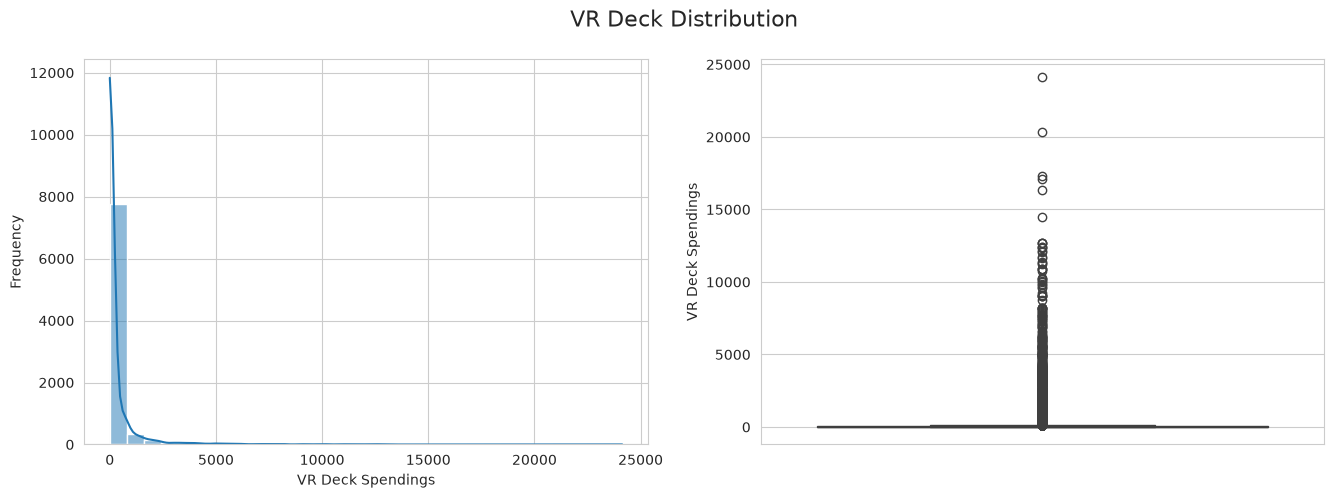

In [56]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("VR Deck Distribution", fontsize=16)

ax = sns.histplot(df["VR_Deck"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("VR Deck Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["VR_Deck"], ax=axes[1])
ax.set_ylabel("VR Deck Spendings")

plt.show()

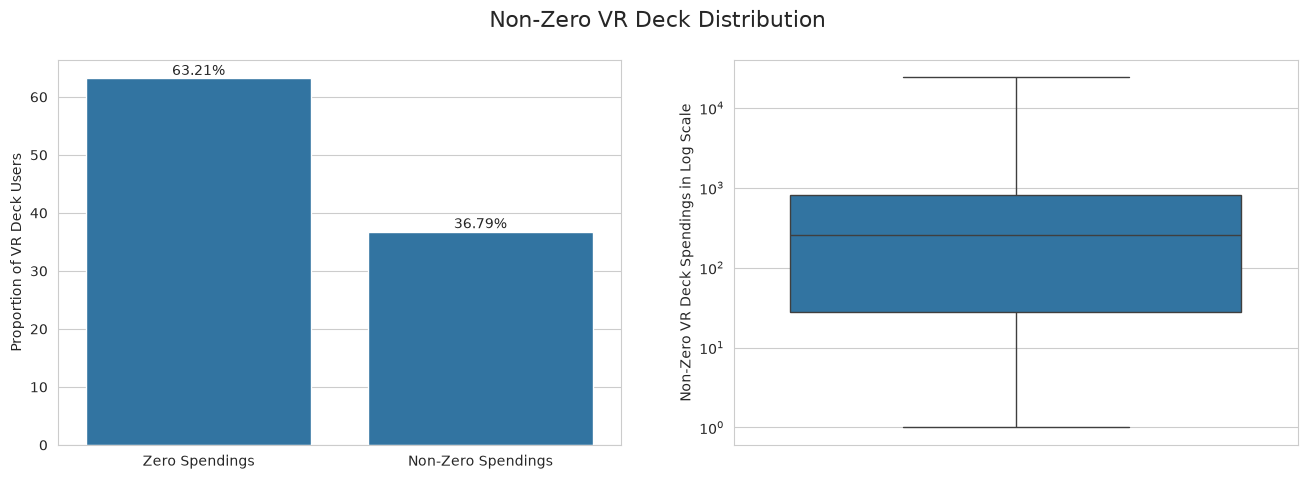

In [57]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero VR Deck Distribution", fontsize=16)

vr_deck_proportion = (df["VR_Deck"] == 0).value_counts(normalize=True) * 100
vr_deck_proportion = vr_deck_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(vr_deck_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of VR Deck Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("VR_Deck > 0")["VR_Deck"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero VR Deck Spendings in Log Scale")

plt.show()

#### Cabin Deck

In [58]:
df["Cabin_Deck"].value_counts(dropna=False)

Cabin_Deck
F      2794
G      2559
E       876
B       779
C       747
D       478
A       256
NaN     199
T         5
Name: count, dtype: int64

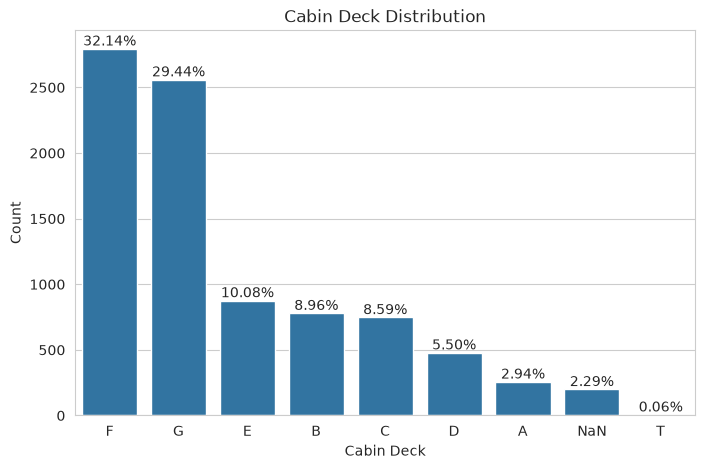

In [59]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Deck"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Deck"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Deck Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Deck")
plt.show()

#### Cabin Num

In [60]:
df["Cabin_Num"].describe()

count        8494.0
mean     600.367671
std      511.867226
min             0.0
25%          167.25
50%           427.0
75%           999.0
max          1894.0
Name: Cabin_Num, dtype: Float64

In [61]:
df["Cabin_Num"].isna().sum()

np.int64(199)

In [62]:
df["Cabin_Num"].value_counts(dropna=False)

Cabin_Num
<NA>    199
82       28
19       22
86       22
56       21
       ... 
1886      1
1891      1
1892      1
1893      1
1894      1
Name: count, Length: 1818, dtype: Int64

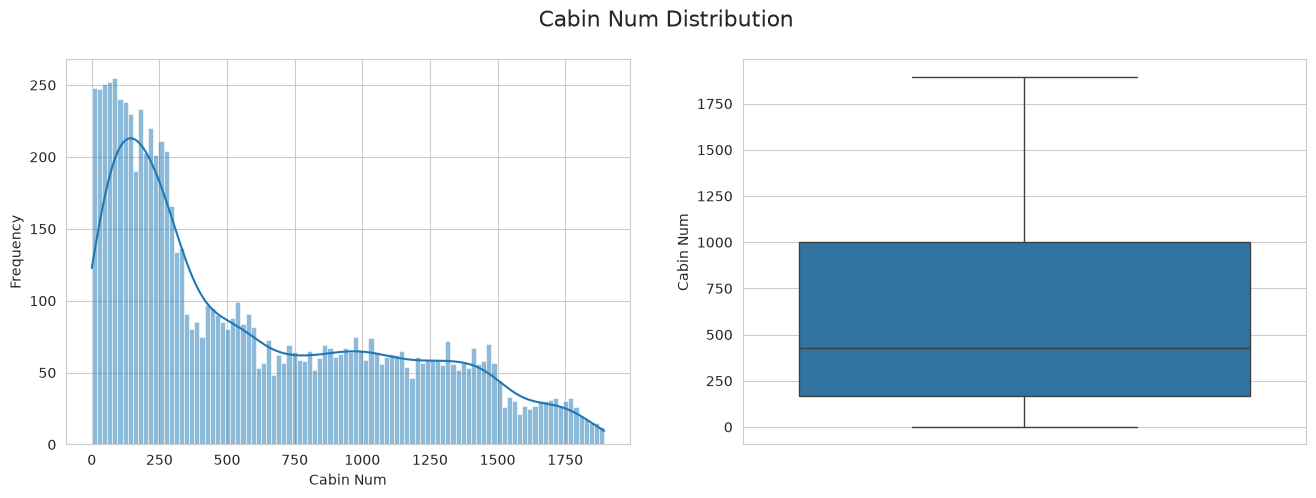

In [63]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Cabin Num Distribution", fontsize=16)

ax = sns.histplot(df["Cabin_Num"], ax=axes[0], bins=100, kde=True)
ax.set_xlabel("Cabin Num")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Cabin_Num"], ax=axes[1])
ax.set_ylabel("Cabin Num")

plt.show()

#### Cabin Side

In [64]:
df["Cabin_Side"].value_counts(dropna=False)

Cabin_Side
S      4288
P      4206
NaN     199
Name: count, dtype: int64

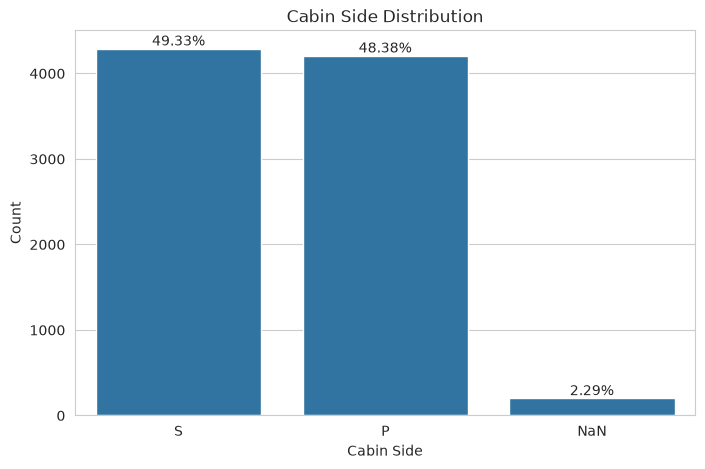

In [65]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Side"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Side"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Side Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Side")
plt.show()

#### Cabin Group Size

In [66]:
df["Cabin_Group_Size"].value_counts(dropna=False)

Cabin_Group_Size
1      5427
2      1372
3       747
4       416
5       235
NaN     199
6       198
7        91
8         8
Name: count, dtype: int64

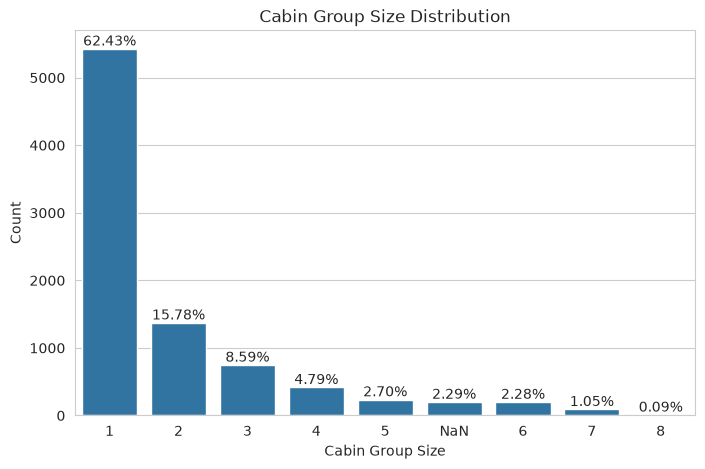

In [67]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Group_Size"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Group_Size"].value_counts(dropna=False).sum() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Group Size Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Group Size")
plt.show()

#### Passenger Group ID

In [68]:
df["Passenger_Group_ID"].describe()

count         8693.0
mean     4633.389624
std      2671.028856
min              1.0
25%           2319.0
50%           4630.0
75%           6883.0
max           9280.0
Name: Passenger_Group_ID, dtype: Float64

In [69]:
df["Passenger_Group_ID"].isna().sum()

np.int64(0)

In [70]:
df["Passenger_Group_ID"].value_counts(dropna=False)

Passenger_Group_ID
984     8
4005    8
4256    8
4498    8
5133    8
       ..
9270    1
9274    1
9276    1
9278    1
9279    1
Name: count, Length: 6217, dtype: Int64

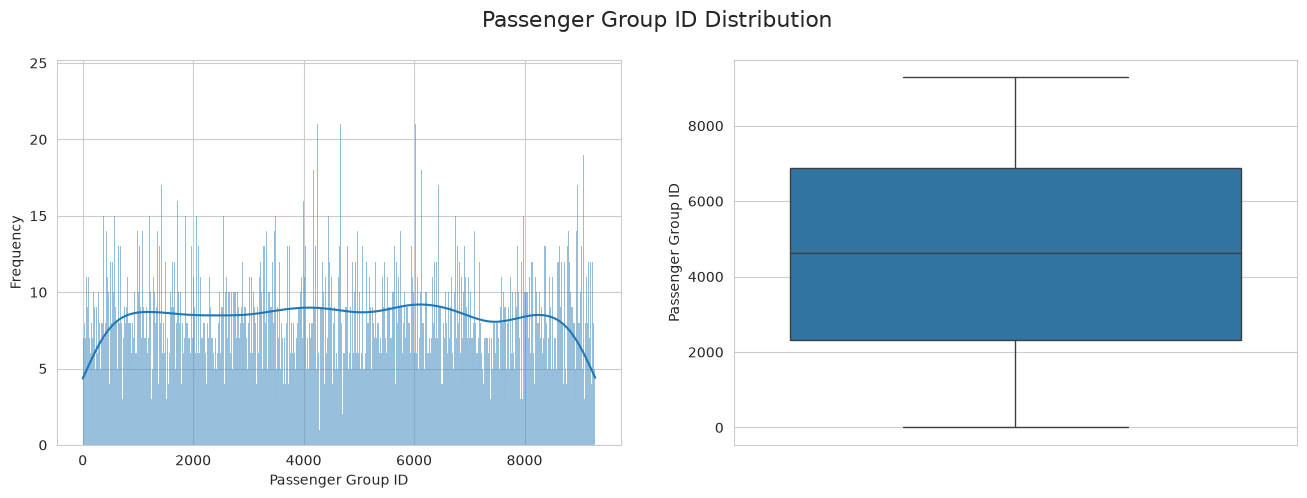

In [71]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Passenger Group ID Distribution", fontsize=16)

ax = sns.histplot(df["Passenger_Group_ID"], ax=axes[0], bins=1000, kde=True)
ax.set_xlabel("Passenger Group ID")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Passenger_Group_ID"], ax=axes[1])
ax.set_ylabel("Passenger Group ID")

plt.show()

#### Passenger Group Position

In [72]:
df["Passenger_Group_Position"].value_counts(dropna=False)

Passenger_Group_Position
1    6217
2    1412
3     571
4     231
5     128
6      75
7      46
8      13
Name: count, dtype: int64

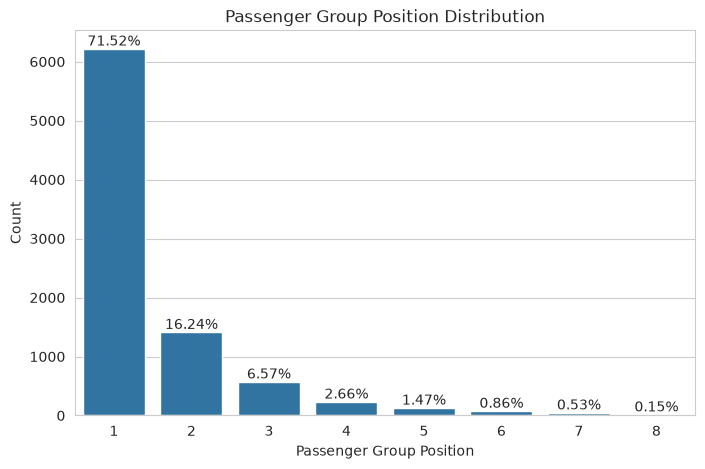

In [73]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Passenger_Group_Position"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Passenger_Group_Position"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Passenger Group Position Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Passenger Group Position")
plt.show()

#### Travel Group Size

In [74]:
df["Travel_Group_Size"].value_counts(dropna=False)

Travel_Group_Size
1    4805
2    1682
3    1020
4     412
5     265
7     231
6     174
8     104
Name: count, dtype: int64

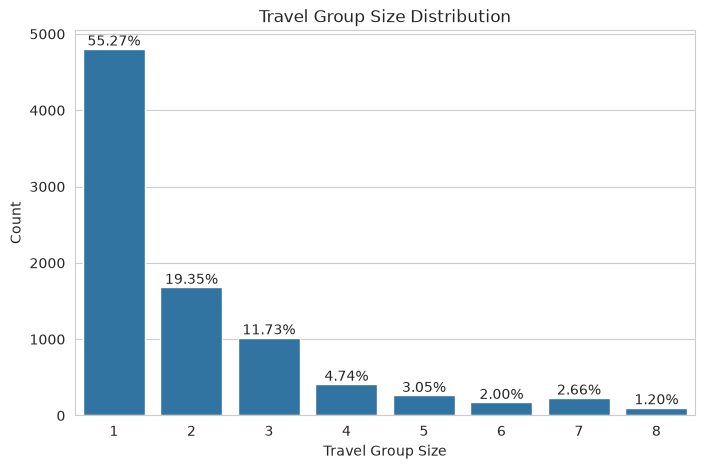

In [75]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Travel_Group_Size"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Travel_Group_Size"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Travel Group Size Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Travel Group Size")
plt.show()

#### Transported

In [76]:
df["Transported"].value_counts(dropna=False)

Transported
True     4378
False    4315
Name: count, dtype: int64

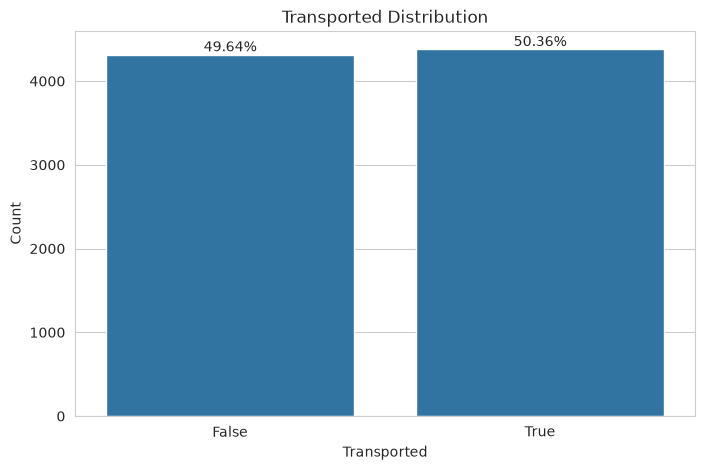

In [77]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Transported"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Transported"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Transported Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Transported")
plt.show()

### Bivariate Analysis

#### Home Planet vs Transported

In [78]:
home_planet_crosstab = pd.crosstab(index=df["Transported"], columns=df["Home_Planet"], margins=True)
home_planet_crosstab = home_planet_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
home_planet_crosstab

,Earth,Europa,Mars,Total Cols
Not Transported,2651,727,839,4217
Transported,1951,1404,920,4275
Total Rows,4602,2131,1759,8492


In [79]:
home_planet_prob = home_planet_crosstab / home_planet_crosstab.loc["Total Rows"]
home_planet_prob

,Earth,Europa,Mars,Total Cols
Not Transported,0.576054,0.341154,0.476976,0.496585
Transported,0.423946,0.658846,0.523024,0.503415
Total Rows,1.000000,1.000000,1.000000,1.000000


In [80]:
home_planet_prob = home_planet_prob.stack()["Transported"].drop("Total Cols")

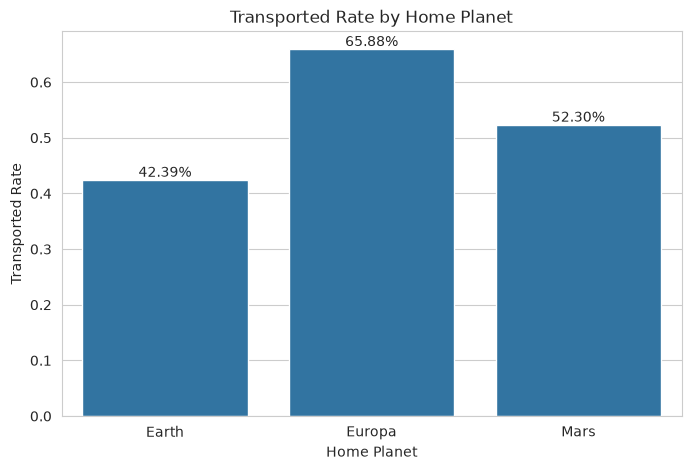

In [81]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(home_planet_prob)
ax.bar_label(ax.containers[0], labels=home_planet_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Home Planet")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Home Planet")
plt.show()

#### Destination vs Transported

In [82]:
destination_crosstab = pd.crosstab(index=df["Transported"], columns=df["Destination"], margins=True)
destination_crosstab = destination_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
destination_crosstab

,55 Cancri e,PSO J318.5-22,TRAPPIST-1e,Total Cols
Not Transported,702,395,3128,4225
Transported,1098,401,2787,4286
Total Rows,1800,796,5915,8511


In [83]:
destination_prob = destination_crosstab / destination_crosstab.loc["Total Rows"]
destination_prob

,55 Cancri e,PSO J318.5-22,TRAPPIST-1e,Total Cols
Not Transported,0.39,0.496231,0.528825,0.496416
Transported,0.61,0.503769,0.471175,0.503584
Total Rows,1.00,1.000000,1.000000,1.000000


In [84]:
destination_prob = destination_prob.stack()["Transported"].drop("Total Cols")

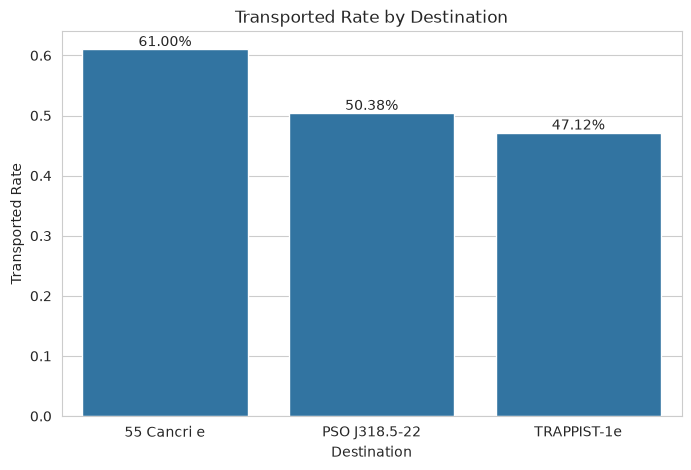

In [85]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(destination_prob)
ax.bar_label(ax.containers[0], labels=destination_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Destination")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Destination")
plt.show()

#### Age vs Transported

In [86]:
age_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Age"], range(0, int(df["Age"].max()) + 10, 10), include_lowest=True), margins=True)
age_crosstab = age_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
age_crosstab

,"(-0.001, 10.0]","(10.0, 20.0]","(20.0, 30.0]","(30.0, 40.0]","(40.0, 50.0]","(50.0, 60.0]","(60.0, 70.0]","(70.0, 80.0]",Total Cols
Not Transported,210,828,1416,893,499,264,93,23,4226
Transported,508,889,1252,787,495,253,90,14,4288
Total Rows,718,1717,2668,1680,994,517,183,37,8514


In [87]:
age_prob = age_crosstab / age_crosstab.loc["Total Rows"]
age_prob

,"(-0.001, 10.0]","(10.0, 20.0]","(20.0, 30.0]","(30.0, 40.0]","(40.0, 50.0]","(50.0, 60.0]","(60.0, 70.0]","(70.0, 80.0]",Total Cols
Not Transported,0.292479,0.482236,0.530735,0.531548,0.502012,0.510638,0.508197,0.621622,0.496359
Transported,0.707521,0.517764,0.469265,0.468452,0.497988,0.489362,0.491803,0.378378,0.503641
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [88]:
age_prob = age_prob.stack()["Transported"].drop("Total Cols")
age_prob.index = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80"]

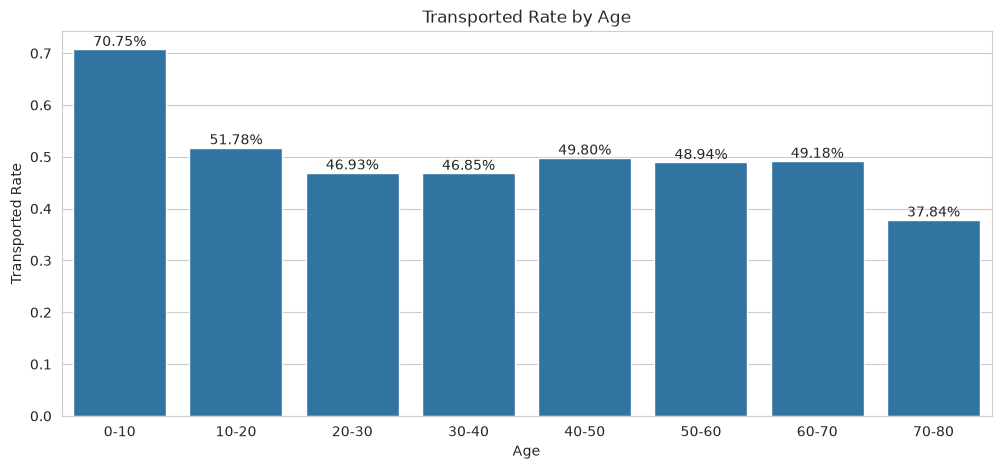

In [89]:
plt.figure(figsize=(12, 5))
ax = sns.barplot(age_prob)
ax.bar_label(ax.containers[0], age_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Age")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Age")
plt.show()

#### Cryo Sleep vs Transported

In [90]:
cryo_sleep_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cryo_Sleep"], margins=True)
cryo_sleep_crosstab = cryo_sleep_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    }, 
    columns={
        False: "Not Sleep",
        True: "Sleep",
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cryo_sleep_crosstab

,Not Sleep,Sleep,Total Cols
Not Transported,3650,554,4204
Transported,1789,2483,4272
Total Rows,5439,3037,8476


In [91]:
cryo_sleep_prob = cryo_sleep_crosstab / cryo_sleep_crosstab.loc["Total Rows"]
cryo_sleep_prob

,Not Sleep,Sleep,Total Cols
Not Transported,0.671079,0.182417,0.495989
Transported,0.328921,0.817583,0.504011
Total Rows,1.000000,1.000000,1.000000


In [92]:
cryo_sleep_prob = cryo_sleep_prob.stack()["Transported"].drop("Total Cols")

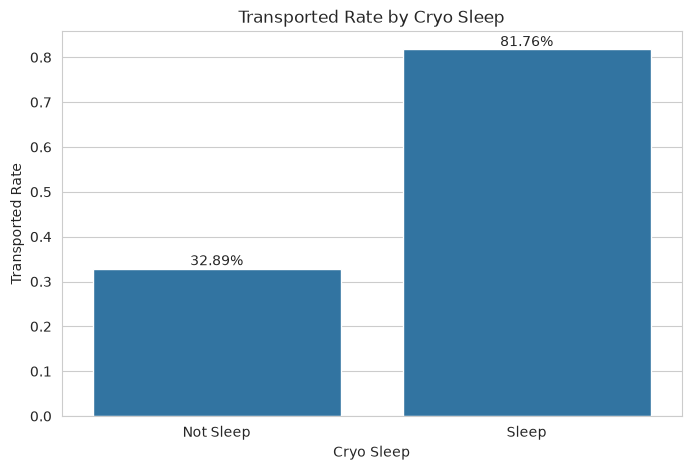

In [93]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cryo_sleep_prob)
ax.bar_label(ax.containers[0], labels=cryo_sleep_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cryo Sleep")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cryo Sleep")
plt.show()

#### VIP vs Transported

In [94]:
vip_crosstab = pd.crosstab(index=df["Transported"], columns=df["VIP"], margins=True)
vip_crosstab = vip_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    }, 
    columns={
        False: "Not VIP",
        True: "VIP",
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
vip_crosstab

,Not VIP,VIP,Total Cols
Not Transported,4093,123,4216
Transported,4198,76,4274
Total Rows,8291,199,8490


In [95]:
vip_prob = vip_crosstab / vip_crosstab.loc["Total Rows"]
vip_prob

,Not VIP,VIP,Total Cols
Not Transported,0.493668,0.61809,0.496584
Transported,0.506332,0.38191,0.503416
Total Rows,1.000000,1.00000,1.000000


In [96]:
vip_prob = vip_prob.stack()["Transported"].drop("Total Cols")

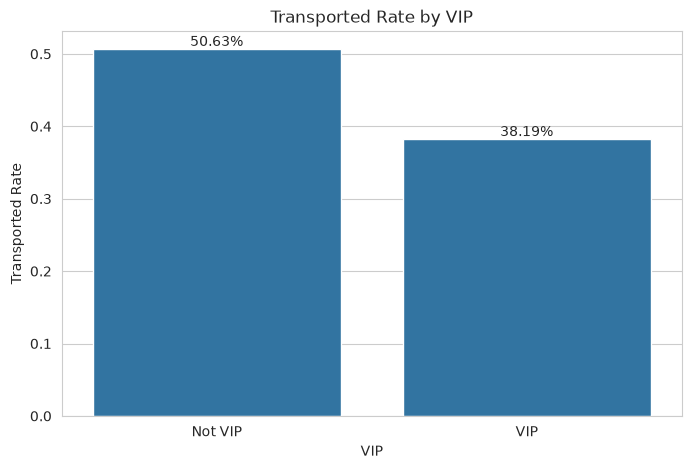

In [97]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(vip_prob)
ax.bar_label(ax.containers[0], labels=vip_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by VIP")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("VIP")
plt.show()

#### Room Service vs Transported

In [98]:
room_service_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Room_Service"], [0, 0.1, df["Room_Service"].max()], include_lowest=True), margins=True)
room_service_crosstab = room_service_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
room_service_crosstab

,"(-0.001, 0.1]","(0.1, 14327.0]",Total Cols
Not Transported,2045,2172,4217
Transported,3532,763,4295
Total Rows,5577,2935,8512


In [99]:
room_service_prob = room_service_crosstab / room_service_crosstab.loc["Total Rows"]
room_service_prob

,"(-0.001, 0.1]","(0.1, 14327.0]",Total Cols
Not Transported,0.366685,0.740034,0.495418
Transported,0.633315,0.259966,0.504582
Total Rows,1.000000,1.000000,1.000000


In [100]:
room_service_prob = room_service_prob.stack()["Transported"].drop("Total Cols")
room_service_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

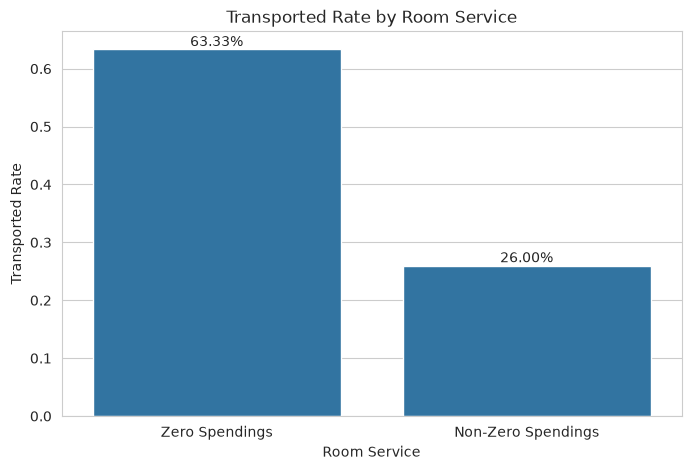

In [101]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(room_service_prob)
ax.bar_label(ax.containers[0], labels=room_service_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Room Service")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Room Service")
plt.show()

#### Food Court vs Transported

In [102]:
food_court_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Food_Court"], [0, 0.1, df["Food_Court"].max()], include_lowest=True), margins=True)
food_court_crosstab = food_court_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
food_court_crosstab

,"(-0.001, 0.1]","(0.1, 29813.0]",Total Cols
Not Transported,2232,1999,4231
Transported,3224,1055,4279
Total Rows,5456,3054,8510


In [103]:
food_court_prob = food_court_crosstab / food_court_crosstab.loc["Total Rows"]
food_court_prob

,"(-0.001, 0.1]","(0.1, 29813.0]",Total Cols
Not Transported,0.409091,0.654551,0.49718
Transported,0.590909,0.345449,0.50282
Total Rows,1.000000,1.000000,1.00000


In [104]:
food_court_prob = food_court_prob.stack()["Transported"].drop("Total Cols")
food_court_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

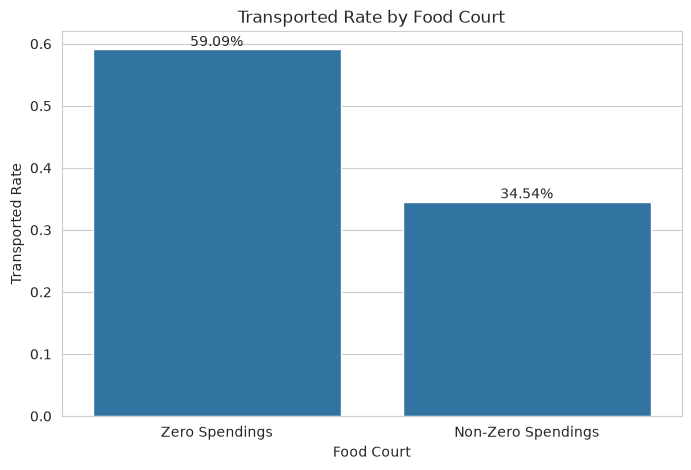

In [105]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(food_court_prob)
ax.bar_label(ax.containers[0], labels=food_court_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Food Court")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Food Court")
plt.show()

#### Shopping Mall vs Transported

In [106]:
shopping_mall_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Shopping_Mall"], [0, 0.1, df["Shopping_Mall"].max()], include_lowest=True), margins=True)
shopping_mall_crosstab = shopping_mall_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
shopping_mall_crosstab

,"(-0.001, 0.1]","(0.1, 23492.0]",Total Cols
Not Transported,2242,1979,4221
Transported,3345,919,4264
Total Rows,5587,2898,8485


In [107]:
shopping_mall_prob = shopping_mall_crosstab / shopping_mall_crosstab.loc["Total Rows"]
shopping_mall_prob

,"(-0.001, 0.1]","(0.1, 23492.0]",Total Cols
Not Transported,0.401289,0.682885,0.497466
Transported,0.598711,0.317115,0.502534
Total Rows,1.000000,1.000000,1.000000


In [108]:
shopping_mall_prob = shopping_mall_prob.stack()["Transported"].drop("Total Cols")
shopping_mall_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

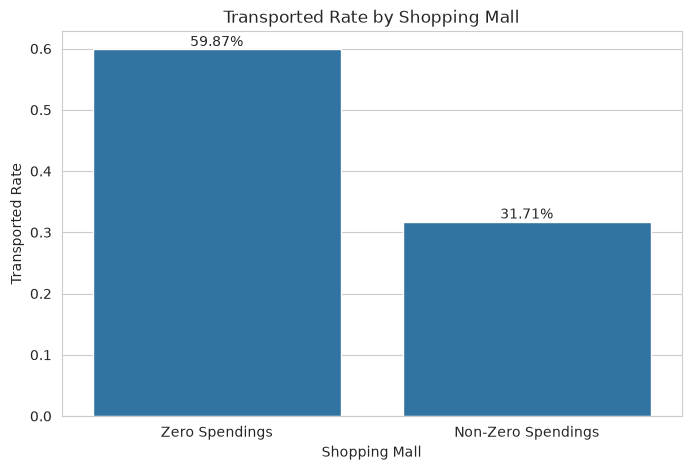

In [109]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(shopping_mall_prob)
ax.bar_label(ax.containers[0], labels=shopping_mall_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Shopping Mall")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Shopping Mall")
plt.show()

#### Spa vs Transported

In [110]:
spa_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Spa"], [0, 0.1, df["Spa"].max()], include_lowest=True), margins=True)
spa_crosstab = spa_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
spa_crosstab

,"(-0.001, 0.1]","(0.1, 22408.0]",Total Cols
Not Transported,1921,2302,4223
Transported,3403,884,4287
Total Rows,5324,3186,8510


In [111]:
spa_prob = spa_crosstab / spa_crosstab.loc["Total Rows"]
spa_prob

,"(-0.001, 0.1]","(0.1, 22408.0]",Total Cols
Not Transported,0.360819,0.722536,0.49624
Transported,0.639181,0.277464,0.50376
Total Rows,1.000000,1.000000,1.00000


In [112]:
spa_prob = spa_prob.stack()["Transported"].drop("Total Cols")
spa_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

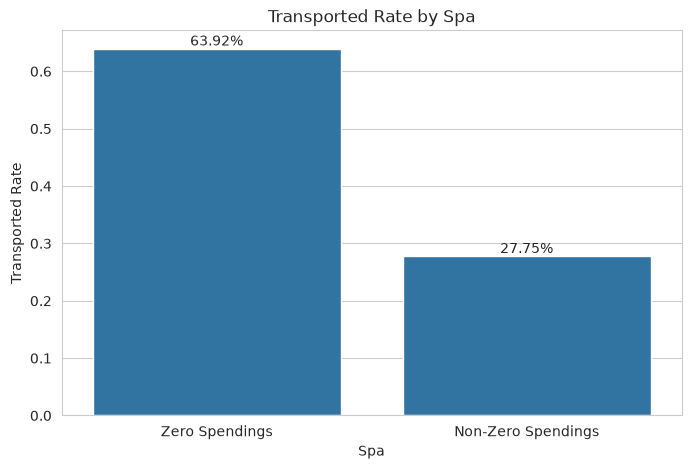

In [113]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(spa_prob)
ax.bar_label(ax.containers[0], labels=spa_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Spa")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Spa")
plt.show()

#### VR Deck vs Transported

In [114]:
vr_deck_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["VR_Deck"], [0, 0.1, df["VR_Deck"].max()], include_lowest=True), margins=True)
vr_deck_crosstab = vr_deck_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
vr_deck_crosstab

,"(-0.001, 0.1]","(0.1, 24133.0]",Total Cols
Not Transported,2044,2181,4225
Transported,3451,829,4280
Total Rows,5495,3010,8505


In [115]:
vr_deck_prob = vr_deck_crosstab / vr_deck_crosstab.loc["Total Rows"]
vr_deck_prob

,"(-0.001, 0.1]","(0.1, 24133.0]",Total Cols
Not Transported,0.371975,0.724585,0.496767
Transported,0.628025,0.275415,0.503233
Total Rows,1.000000,1.000000,1.000000


In [116]:
vr_deck_prob = vr_deck_prob.stack()["Transported"].drop("Total Cols")
vr_deck_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

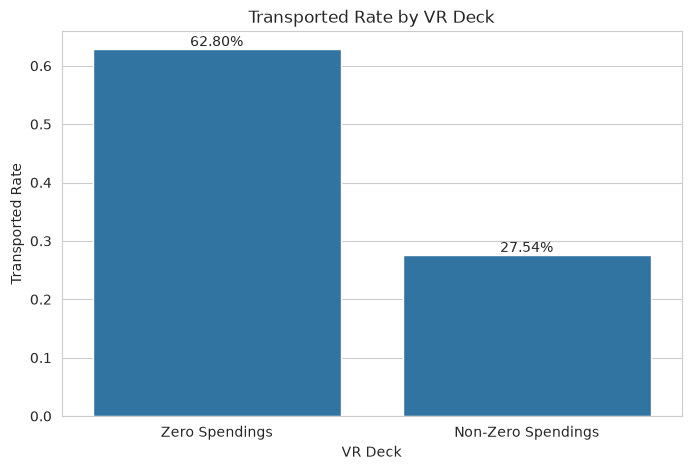

In [117]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(vr_deck_prob)
ax.bar_label(ax.containers[0], labels=vr_deck_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by VR Deck")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("VR Deck")
plt.show()

#### Cabin Deck vs Transported

In [118]:
cabin_deck_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Deck"], margins=True)
cabin_deck_crosstab = cabin_deck_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_deck_crosstab

,A,B,C,D,E,F,G,T,Total Cols
Not Transported,129,207,239,271,563,1565,1238,4,4216
Transported,127,572,508,207,313,1229,1321,1,4278
Total Rows,256,779,747,478,876,2794,2559,5,8494


In [119]:
cabin_deck_prob = cabin_deck_crosstab / cabin_deck_crosstab.loc["Total Rows"]
cabin_deck_prob

,A,B,C,D,E,F,G,T,Total Cols
Not Transported,0.503906,0.265725,0.319946,0.566946,0.642694,0.560129,0.483783,0.8,0.49635
Transported,0.496094,0.734275,0.680054,0.433054,0.357306,0.439871,0.516217,0.2,0.50365
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.00000


In [120]:
cabin_deck_prob = cabin_deck_prob.stack()["Transported"].drop("Total Cols")

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_deck_prob)
ax.bar_label(ax.containers[0], labels=cabin_deck_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Deck")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Deck")
plt.show()

#### Cabin Num vs Transported

In [198]:
cabin_num_crosstab = pd.crosstab(index=df["Transported"], columns=pd.qcut(df["Cabin_Num"], 10), margins=True)
cabin_num_crosstab = cabin_num_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_num_crosstab

,"(-0.001, 64.0]","(64.0, 129.0]","(129.0, 204.0]","(204.0, 282.0]","(282.0, 427.0]","(427.0, 610.8]","(610.8, 876.0]","(876.0, 1126.0]","(1126.0, 1405.7]","(1405.7, 1894.0]",Total Cols
Not Transported,409,387,391,384,470,500,391,314,468,502,4216
Transported,450,457,455,467,380,346,460,537,378,348,4278
Total Rows,859,844,846,851,850,846,851,851,846,850,8494


In [199]:
cabin_num_prob = cabin_num_crosstab / cabin_num_crosstab.loc["Total Rows"]
cabin_num_prob

,"(-0.001, 64.0]","(64.0, 129.0]","(129.0, 204.0]","(204.0, 282.0]","(282.0, 427.0]","(427.0, 610.8]","(610.8, 876.0]","(876.0, 1126.0]","(1126.0, 1405.7]","(1405.7, 1894.0]",Total Cols
Not Transported,0.476135,0.458531,0.462175,0.451234,0.552941,0.591017,0.459459,0.368978,0.553191,0.590588,0.49635
Transported,0.523865,0.541469,0.537825,0.548766,0.447059,0.408983,0.540541,0.631022,0.446809,0.409412,0.50365
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [200]:
cabin_num_prob = cabin_num_prob.stack()["Transported"].drop("Total Cols")

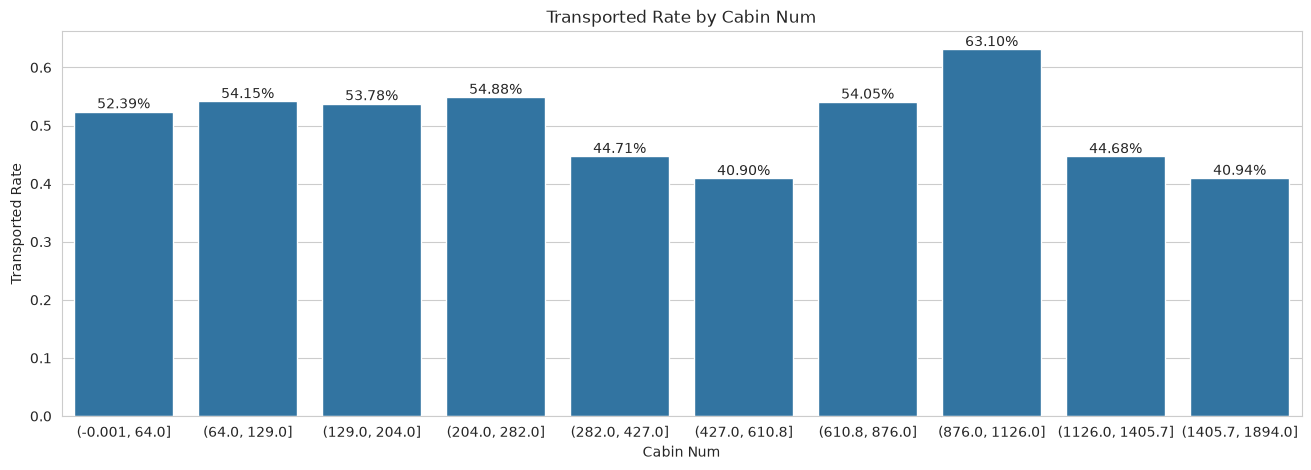

In [208]:
plt.figure(figsize=(16, 5))
ax = sns.barplot(cabin_num_prob)
ax.bar_label(ax.containers[0], cabin_num_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Num")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Num")
plt.show()

#### Cabin Side vs Transported

In [122]:
cabin_side_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Side"], margins=True)
cabin_side_crosstab = cabin_side_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_side_crosstab

,P,S,Total Cols
Not Transported,2308,1908,4216
Transported,1898,2380,4278
Total Rows,4206,4288,8494


In [123]:
cabin_side_prob = cabin_side_crosstab / cabin_side_crosstab.loc["Total Rows"]
cabin_side_prob

,P,S,Total Cols
Not Transported,0.54874,0.444963,0.49635
Transported,0.45126,0.555037,0.50365
Total Rows,1.00000,1.000000,1.00000


In [124]:
cabin_side_prob = cabin_side_prob.stack()["Transported"].drop("Total Cols")

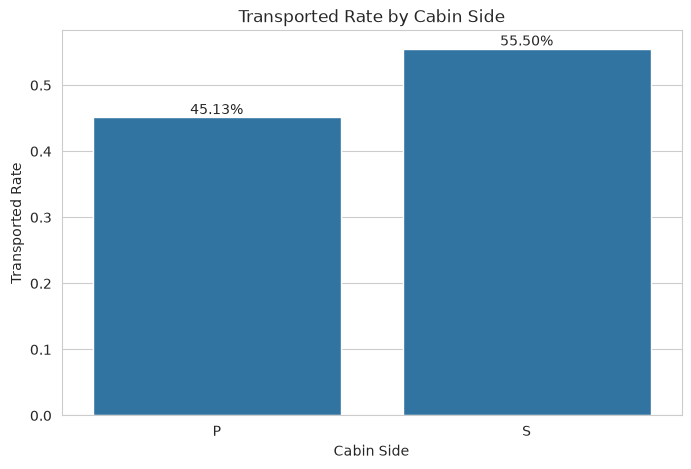

In [125]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_side_prob)
ax.bar_label(ax.containers[0], labels=cabin_side_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Side")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Side")
plt.show()

#### Cabin Group Size vs Transported

In [126]:
cabin_group_size_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Group_Size"], margins=True)
cabin_group_size_crosstab = cabin_group_size_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_group_size_crosstab

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,3009,555,290,152,93,73,39,5,4216
Transported,2418,817,457,264,142,125,52,3,4278
Total Rows,5427,1372,747,416,235,198,91,8,8494


In [127]:
cabin_group_size_prob = cabin_group_size_crosstab / cabin_group_size_crosstab.loc["Total Rows"]
cabin_group_size_prob

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,0.55445,0.404519,0.38822,0.365385,0.395745,0.368687,0.428571,0.625,0.49635
Transported,0.44555,0.595481,0.61178,0.634615,0.604255,0.631313,0.571429,0.375,0.50365
Total Rows,1.00000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000,1.00000


In [128]:
cabin_group_size_prob = cabin_group_size_prob.stack()["Transported"].drop("Total Cols")

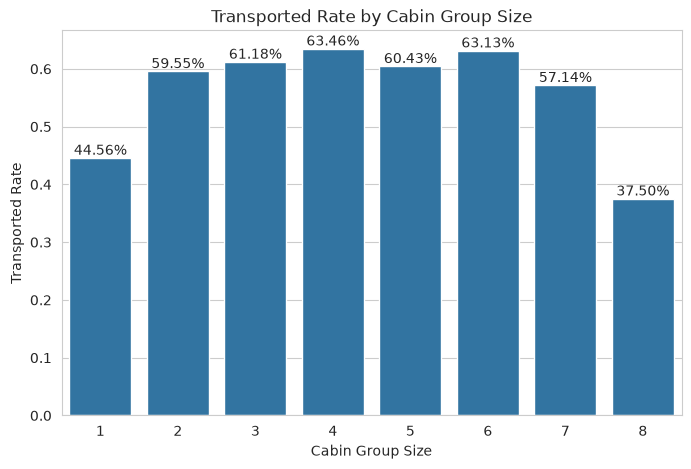

In [129]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_group_size_prob)
ax.bar_label(ax.containers[0], labels=cabin_group_size_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Group Size")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Group Size")
plt.show()

#### Passenger Group Position vs Transported

In [130]:
passenger_group_position_crosstab = pd.crosstab(index=df["Transported"], columns=df["Passenger_Group_Position"], margins=True)
passenger_group_position_crosstab = passenger_group_position_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
passenger_group_position_crosstab

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,3258,623,218,94,58,34,23,7,4315
Transported,2959,789,353,137,70,41,23,6,4378
Total Rows,6217,1412,571,231,128,75,46,13,8693


In [131]:
passenger_group_position_crosstab = passenger_group_position_crosstab / passenger_group_position_crosstab.loc["Total Rows"]
passenger_group_position_crosstab

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,0.524047,0.441218,0.381786,0.406926,0.453125,0.453333,0.5,0.538462,0.496376
Transported,0.475953,0.558782,0.618214,0.593074,0.546875,0.546667,0.5,0.461538,0.503624
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.000000


In [132]:
passenger_group_position_prob = passenger_group_position_crosstab.stack()["Transported"].drop("Total Cols")

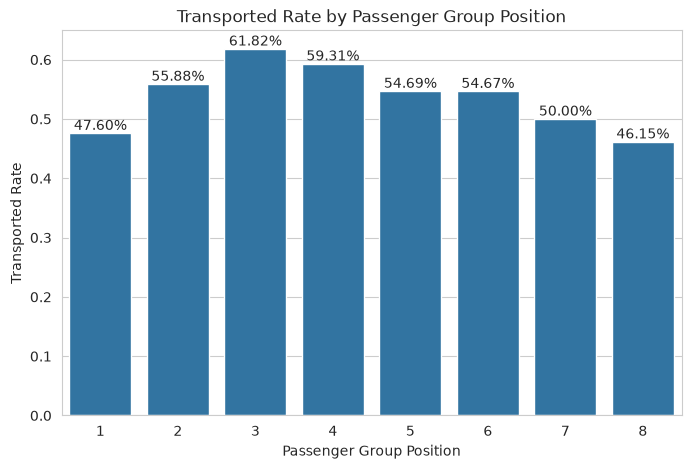

In [133]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(passenger_group_position_prob)
ax.bar_label(ax.containers[0], labels=passenger_group_position_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Passenger Group Position")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Passenger Group Position")
plt.show()

#### Travel Group Size vs Transported

In [134]:
travel_group_size_crosstab = pd.crosstab(index=df["Transported"], columns=df["Travel_Group_Size"], margins=True)
travel_group_size_crosstab = travel_group_size_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
travel_group_size_crosstab

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,2631,777,415,148,108,67,106,63,4315
Transported,2174,905,605,264,157,107,125,41,4378
Total Rows,4805,1682,1020,412,265,174,231,104,8693


In [135]:
travel_group_size_crosstab = travel_group_size_crosstab / travel_group_size_crosstab.loc["Total Rows"]
travel_group_size_crosstab

,1,2,3,4,5,6,7,8,Total Cols
Not Transported,0.547555,0.46195,0.406863,0.359223,0.407547,0.385057,0.458874,0.605769,0.496376
Transported,0.452445,0.53805,0.593137,0.640777,0.592453,0.614943,0.541126,0.394231,0.503624
Total Rows,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [136]:
travel_group_size_prob = travel_group_size_crosstab.stack()["Transported"].drop("Total Cols")

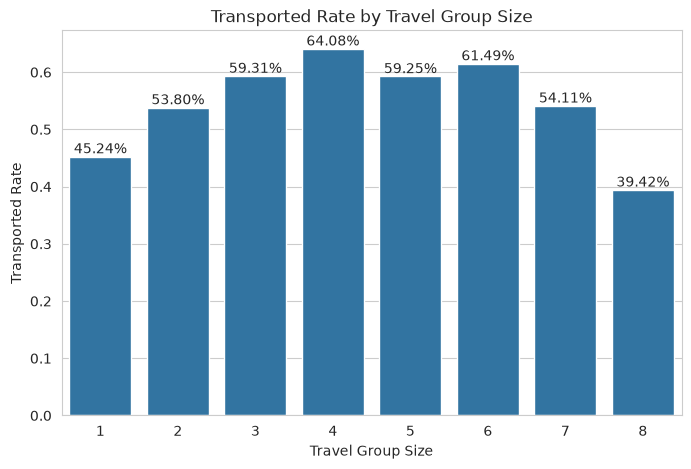

In [137]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(travel_group_size_prob)
ax.bar_label(ax.containers[0], labels=travel_group_size_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Travel Group Size")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Travel Group Size")
plt.show()

#### Cabin_Group_Size vs Travel_Group_Size

In [138]:
groups_crosstab = pd.crosstab(index=df["Cabin_Group_Size"], columns=df["Travel_Group_Size"])
groups_crosstab = groups_crosstab.rename(
    index={i: f"Cabin_Group_Size_{i}" for i in groups_crosstab.index},
    columns={c: f"Travel_Group_Size_{c}" for c in groups_crosstab.columns},
).rename_axis(index=None, columns=None)
groups_crosstab

,Travel_Group_Size_1,Travel_Group_Size_2,Travel_Group_Size_3,Travel_Group_Size_4,Travel_Group_Size_5,Travel_Group_Size_6,Travel_Group_Size_7,Travel_Group_Size_8
Cabin_Group_Size_1,4706,535,132,19,13,6,15,1
Cabin_Group_Size_2,0,1100,216,20,18,0,14,4
Cabin_Group_Size_3,0,0,654,63,12,0,6,12
Cabin_Group_Size_4,0,0,0,304,68,0,4,40
Cabin_Group_Size_5,0,0,0,0,140,50,35,10
Cabin_Group_Size_6,0,0,0,0,0,114,66,18
Cabin_Group_Size_7,0,0,0,0,0,0,84,7
Cabin_Group_Size_8,0,0,0,0,0,0,0,8


<Axes: >

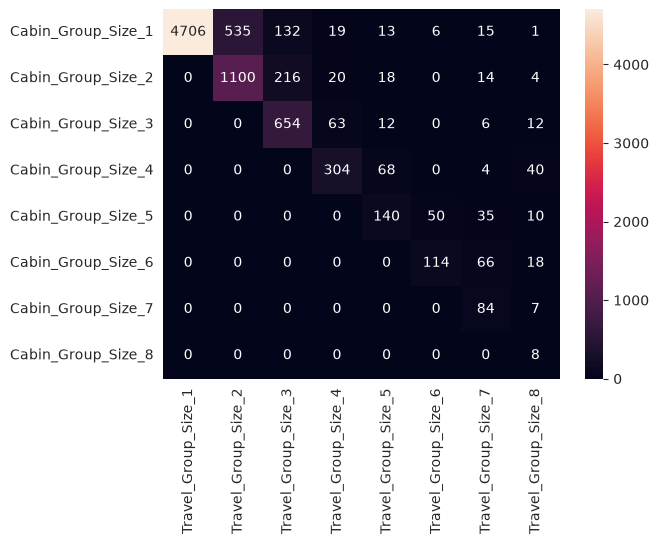

In [139]:
sns.heatmap(groups_crosstab, annot=True, fmt="d")

In [140]:
groups_df = df.dropna(subset=["Cabin_Group_Size", "Travel_Group_Size"])

(groups_df["Cabin_Group_Size"].astype("float") - groups_df["Travel_Group_Size"].astype("float")).value_counts(normalize=True)

 0.0    0.837061
-1.0    0.118319
-2.0    0.025547
-4.0    0.006946
-3.0    0.006004
-5.0    0.003767
-6.0    0.002237
-7.0    0.000118
Name: proportion, dtype: float64

So 83.7% of travellers have the same amount of people in their group and in their cabin.

### Multivariate Analysis

In [141]:
# sns.pairplot(df, vars=["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], hue="Transported")
# plt.show()

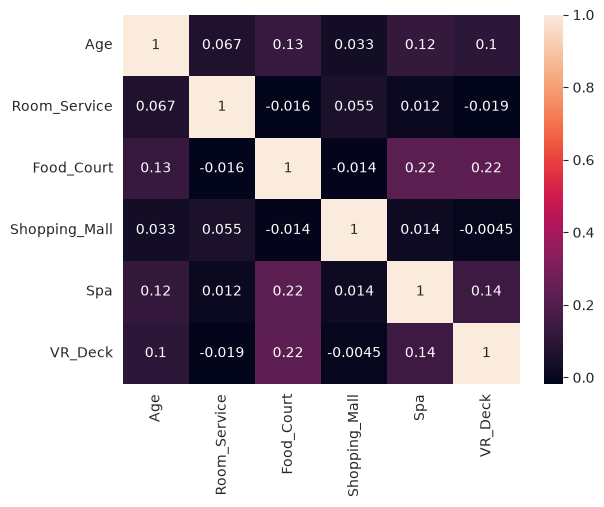

In [142]:
sns.heatmap(df[["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"]].dropna().corr(), annot=True)
plt.show()

In [143]:
df.select_dtypes(include='number').skew()

Age                    0.419097
Room_Service           6.333014
Food_Court             7.102228
Shopping_Mall         12.627562
Spa                     7.63602
VR_Deck                7.819732
Cabin_Num               0.71836
Passenger_Group_ID      0.00202
dtype: Float64

In [144]:
df.select_dtypes(include='number').kurt()

Age                     0.101933
Room_Service           65.273802
Food_Court              73.30723
Shopping_Mall         328.870913
Spa                     81.20211
VR_Deck                86.011186
Cabin_Num              -0.712772
Passenger_Group_ID     -1.181746
dtype: Float64

## Feature Transformations

### Dealing with NaN values

In [145]:
df.isna().sum()

Home_Planet                 201
Destination                 182
Age                         179
Cryo_Sleep                  217
VIP                         203
Room_Service                181
Food_Court                  183
Shopping_Mall               208
Spa                         183
VR_Deck                     188
Cabin_Deck                  199
Cabin_Num                   199
Cabin_Side                  199
Cabin_Group_Size            199
Passenger_Group_ID            0
Passenger_Group_Position      0
Travel_Group_Size             0
Transported                   0
dtype: int64

In [146]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Home_Planet               8492 non-null   category
 1   Destination               8511 non-null   category
 2   Age                       8514 non-null   float64 
 3   Cryo_Sleep                8476 non-null   boolean 
 4   VIP                       8490 non-null   boolean 
 5   Room_Service              8512 non-null   float64 
 6   Food_Court                8510 non-null   float64 
 7   Shopping_Mall             8485 non-null   float64 
 8   Spa                       8510 non-null   float64 
 9   VR_Deck                   8505 non-null   float64 
 10  Cabin_Deck                8494 non-null   category
 11  Cabin_Num                 8494 non-null   Int64   
 12  Cabin_Side                8494 non-null   category
 13  Cabin_Group_Size          8494 non-null   category
 14  Pas

In [147]:
home_planet_moda = df["Home_Planet"].value_counts().index[0]
destination_moda = df["Destination"].value_counts().index[0]
cryo_sleep_moda = df["Cryo_Sleep"].value_counts().index[0]
vip_moda = df["VIP"].value_counts().index[0]
cabin_deck_moda = df["Cabin_Deck"].value_counts().index[0]
cabin_side_moda = df["Cabin_Side"].value_counts().index[0]
cabin_group_size_moda = df["Cabin_Group_Size"].value_counts().index[0]
passenger_group_position_moda = df["Passenger_Group_Position"].value_counts().index[0]
travel_group_size_moda = df["Travel_Group_Size"].value_counts().index[0]

age_mean = df["Age"].mean()

room_service_median = df["Room_Service"].median()
food_court_median = df["Food_Court"].median()
shopping_mall_median = df["Shopping_Mall"].median()
spa_median = df["Spa"].median()
vr_deck_median = df["VR_Deck"].median()
cabin_num_median = df["Cabin_Num"].median()

In [148]:
df["Home_Planet"] = df["Home_Planet"].fillna(home_planet_moda)
df["Destination"] = df["Destination"].fillna(destination_moda)
df["Cryo_Sleep"] = df["Cryo_Sleep"].fillna(cryo_sleep_moda)
df["VIP"] = df["VIP"].fillna(vip_moda)
df["Cabin_Deck"] = df["Cabin_Deck"].fillna(cabin_deck_moda)
df["Cabin_Side"] = df["Cabin_Side"].fillna(cabin_side_moda)
df["Cabin_Group_Size"] = df["Cabin_Group_Size"].fillna(cabin_group_size_moda)
df["Passenger_Group_Position"] = df["Passenger_Group_Position"].fillna(passenger_group_position_moda)
df["Travel_Group_Size"] = df["Travel_Group_Size"].fillna(travel_group_size_moda)

df["Age"] = df["Age"].fillna(age_mean)

df["Room_Service"] = df["Room_Service"].fillna(room_service_median)
df["Food_Court"] = df["Food_Court"].fillna(food_court_median)
df["Shopping_Mall"] = df["Shopping_Mall"].fillna(shopping_mall_median)
df["Spa"] = df["Spa"].fillna(spa_median)
df["VR_Deck"] = df["VR_Deck"].fillna(vr_deck_median)
df["Cabin_Num"] = df["Cabin_Num"].fillna(cabin_num_median).astype("int")

In [149]:
df["Cabin_Group_Size"] = df["Cabin_Group_Size"].astype("int").astype("category") # get rid of ".0" part

In [150]:
df.isna().sum()

Home_Planet                 0
Destination                 0
Age                         0
Cryo_Sleep                  0
VIP                         0
Room_Service                0
Food_Court                  0
Shopping_Mall               0
Spa                         0
VR_Deck                     0
Cabin_Deck                  0
Cabin_Num                   0
Cabin_Side                  0
Cabin_Group_Size            0
Passenger_Group_ID          0
Passenger_Group_Position    0
Travel_Group_Size           0
Transported                 0
dtype: int64

### Creating Dummy Columns

In [151]:
df.head()

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size,Passenger_Group_ID,Passenger_Group_Position,Travel_Group_Size,Transported
0,Europa,TRAPPIST-1e,39.0,False,False,0.0,0.0,0.0,0.0,0.0,B,0,P,1,1,1,1,False
1,Earth,TRAPPIST-1e,24.0,False,False,109.0,9.0,25.0,549.0,44.0,F,0,S,1,2,1,1,True
2,Europa,TRAPPIST-1e,58.0,False,True,43.0,3576.0,0.0,6715.0,49.0,A,0,S,2,3,1,2,False
3,Europa,TRAPPIST-1e,33.0,False,False,0.0,1283.0,371.0,3329.0,193.0,A,0,S,2,3,2,2,False
4,Earth,TRAPPIST-1e,16.0,False,False,303.0,70.0,151.0,565.0,2.0,F,1,S,1,4,1,1,True


In [152]:
df = pd.concat([df, pd.get_dummies(df["Home_Planet"], prefix="Home_Planet", dtype="int8")], axis=1)
df = df.drop(["Home_Planet"], axis=1)

In [153]:
df = pd.concat([df, pd.get_dummies(df["Destination"], prefix="Destination", dtype="int8")], axis=1)
df = df.drop(["Destination"], axis=1)

In [154]:
df = pd.concat([df, pd.get_dummies(df["Cabin_Deck"], prefix="Cabin_Deck", dtype="int8")], axis=1)
df = df.drop(["Cabin_Deck"], axis=1)

In [155]:
df = pd.concat([df, pd.get_dummies(df["Cabin_Group_Size"], prefix="Cabin_Group_Size", dtype="int8")], axis=1)
df = df.drop(["Cabin_Group_Size"], axis=1)

In [156]:
df = pd.concat([df, pd.get_dummies(df["Passenger_Group_Position"], prefix="Passenger_Group_Position", dtype="int8")], axis=1)
df = df.drop(["Passenger_Group_Position"], axis=1)

In [157]:
df = pd.concat([df, pd.get_dummies(df["Travel_Group_Size"], prefix="Travel_Group_Size", dtype="int8")], axis=1)
df = df.drop(["Travel_Group_Size"], axis=1)

In [158]:
df.head()

,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Passenger_Group_ID,Transported,Home_Planet_Earth,Home_Planet_Europa,Home_Planet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T,Cabin_Group_Size_1,Cabin_Group_Size_2,Cabin_Group_Size_3,Cabin_Group_Size_4,Cabin_Group_Size_5,Cabin_Group_Size_6,Cabin_Group_Size_7,Cabin_Group_Size_8,Passenger_Group_Position_1,Passenger_Group_Position_2,Passenger_Group_Position_3,Passenger_Group_Position_4,Passenger_Group_Position_5,Passenger_Group_Position_6,Passenger_Group_Position_7,Passenger_Group_Position_8,Travel_Group_Size_1,Travel_Group_Size_2,Travel_Group_Size_3,Travel_Group_Size_4,Travel_Group_Size_5,Travel_Group_Size_6,Travel_Group_Size_7,Travel_Group_Size_8
0,39.0,False,False,0.0,0.0,0.0,0.0,0.0,0,P,1,False,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
1,24.0,False,False,109.0,9.0,25.0,549.0,44.0,0,S,2,True,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,58.0,False,True,43.0,3576.0,0.0,6715.0,49.0,0,S,3,False,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,33.0,False,False,0.0,1283.0,371.0,3329.0,193.0,0,S,3,False,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,16.0,False,False,303.0,70.0,151.0,565.0,2.0,1,S,4,True,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


In [159]:
df.shape

(8693, 50)

### Convert Categories to Categories Codes

In [160]:
#df["Home_Planet"] = df["Home_Planet"].cat.codes
#df["Destination"] = df["Destination"].cat.codes
df["Cabin_Side"] = df["Cabin_Side"].cat.codes

In [161]:
df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("int8")
df["VIP"] = df["VIP"].astype("int8")
df["Transported"] = df["Transported"].astype("int8")

In [162]:
df.head()

,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Passenger_Group_ID,Transported,Home_Planet_Earth,Home_Planet_Europa,Home_Planet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T,Cabin_Group_Size_1,Cabin_Group_Size_2,Cabin_Group_Size_3,Cabin_Group_Size_4,Cabin_Group_Size_5,Cabin_Group_Size_6,Cabin_Group_Size_7,Cabin_Group_Size_8,Passenger_Group_Position_1,Passenger_Group_Position_2,Passenger_Group_Position_3,Passenger_Group_Position_4,Passenger_Group_Position_5,Passenger_Group_Position_6,Passenger_Group_Position_7,Passenger_Group_Position_8,Travel_Group_Size_1,Travel_Group_Size_2,Travel_Group_Size_3,Travel_Group_Size_4,Travel_Group_Size_5,Travel_Group_Size_6,Travel_Group_Size_7,Travel_Group_Size_8
0,39.0,0,0,0.0,0.0,0.0,0.0,0.0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
1,24.0,0,0,109.0,9.0,25.0,549.0,44.0,0,1,2,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,58.0,0,1,43.0,3576.0,0.0,6715.0,49.0,0,1,3,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,33.0,0,0,0.0,1283.0,371.0,3329.0,193.0,0,1,3,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,16.0,0,0,303.0,70.0,151.0,565.0,2.0,1,1,4,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


In [163]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 50 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         8693 non-null   float64
 1   Cryo_Sleep                  8693 non-null   int8   
 2   VIP                         8693 non-null   int8   
 3   Room_Service                8693 non-null   float64
 4   Food_Court                  8693 non-null   float64
 5   Shopping_Mall               8693 non-null   float64
 6   Spa                         8693 non-null   float64
 7   VR_Deck                     8693 non-null   float64
 8   Cabin_Num                   8693 non-null   int64  
 9   Cabin_Side                  8693 non-null   int8   
 10  Passenger_Group_ID          8693 non-null   Int64  
 11  Transported                 8693 non-null   int8   
 12  Home_Planet_Earth           8693 non-null   int8   
 13  Home_Planet_Europa          8693 non-null   

### Normalization

In [164]:
cols_to_scale = ["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Num", "Passenger_Group_ID"]

scaler = StandardScaler().fit(df[cols_to_scale])
df_scaled = df.copy()
df_scaled[cols_to_scale] = pd.DataFrame(scaler.transform(df[cols_to_scale]))
df_scaled.head()

,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Passenger_Group_ID,Transported,Home_Planet_Earth,Home_Planet_Europa,Home_Planet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T,Cabin_Group_Size_1,Cabin_Group_Size_2,Cabin_Group_Size_3,Cabin_Group_Size_4,Cabin_Group_Size_5,Cabin_Group_Size_6,Cabin_Group_Size_7,Cabin_Group_Size_8,Passenger_Group_Position_1,Passenger_Group_Position_2,Passenger_Group_Position_3,Passenger_Group_Position_4,Passenger_Group_Position_5,Passenger_Group_Position_6,Passenger_Group_Position_7,Passenger_Group_Position_8,Travel_Group_Size_1,Travel_Group_Size_2,Travel_Group_Size_3,Travel_Group_Size_4,Travel_Group_Size_5,Travel_Group_Size_6,Travel_Group_Size_7,Travel_Group_Size_8
0,0.709437,0,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,-1.177238,0,-1.734409,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
1,-0.336717,0,0,-0.168073,-0.275387,-0.241771,0.217158,-0.224205,-1.177238,1,-1.734034,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,2.034566,0,1,-0.268001,1.959998,-0.283579,5.695623,-0.219796,-1.177238,1,-1.733660,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,0.290975,0,0,-0.333105,0.523010,0.336851,2.687176,-0.092818,-1.177238,1,-1.733660,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,-0.894666,0,0,0.125652,-0.237159,-0.031059,0.231374,-0.261240,-1.175264,1,-1.733286,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


## Create Preprocessing Functions

In [165]:
def create_features(df: pd.DataFrame) -> pd.DataFrame:
    cabin_splitted = df["Cabin"].str.split("/", expand=True)
    df["Cabin_Deck"] = cabin_splitted[0]
    df["Cabin_Num"] = cabin_splitted[1]
    df["Cabin_Side"] = cabin_splitted[2]

    df["Cabin_Group_Size"] = df["Cabin"].map(df["Cabin"].value_counts())

    passenger_id_splitted = df["PassengerId"].str.split("_", expand=True)
    df["Passenger_Group_ID"] = passenger_id_splitted[0]
    df["Passenger_Group_Position"] = passenger_id_splitted[1]
    df["Travel_Group_Size"] = df["Passenger_Group_ID"].map(df["Passenger_Group_ID"].value_counts())

    return df

In [166]:
def drop_rename_change_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    df = df.drop(columns=["PassengerId", "Passenger_Group_ID", "Cabin", "Name"])

    df = df.rename(columns={
        "HomePlanet": "Home_Planet",
        "CryoSleep": "Cryo_Sleep",
        "RoomService": "Room_Service",
        "FoodCourt": "Food_Court",
        "ShoppingMall": "Shopping_Mall",
        "VRDeck": "VR_Deck",
    })

    cols = [
        "Home_Planet",
        "Destination",
        "Age",
        "Cryo_Sleep",
        "VIP",
        "Room_Service",
        "Food_Court",
        "Shopping_Mall",
        "Spa",
        "VR_Deck",
        "Cabin_Deck",
        "Cabin_Num",
        "Cabin_Side",
        "Cabin_Group_Size",
        "Passenger_Group_Position",
        "Travel_Group_Size",
    ]

    if "Transported" in df.columns:
        cols.append("Transported")

    df = df[cols]

    df["Home_Planet"] = df["Home_Planet"].astype("category")
    df["Destination"] = df["Destination"].astype("category")
    df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("boolean")
    df["VIP"] = df["VIP"].astype("boolean")
    df["Cabin_Deck"] = df["Cabin_Deck"].astype("category")
    df["Cabin_Num"] = df["Cabin_Num"].astype("Int64")
    df["Cabin_Side"] = df["Cabin_Side"].astype("category")
    df["Cabin_Group_Size"] = df["Cabin_Group_Size"].astype("Int64").astype("category")
    df["Passenger_Group_Position"] = df["Passenger_Group_Position"].astype("Int64").astype("category")
    df["Travel_Group_Size"] = df["Travel_Group_Size"].astype("category")

    return df

In [167]:
def fill_missing_values(df: pd.DataFrame, train_stats: dict[str, str | float] | None = None) -> tuple[pd.DataFrame, dict[str, str | float]]:
    categorical_stats = {
        "Home_Planet": "home_planet_moda",
        "Destination": "destination_moda",
        "Cryo_Sleep": "cryo_sleep_moda",
        "VIP": "vip_moda",
        "Cabin_Deck": "cabin_deck_moda",
        "Cabin_Side": "cabin_side_moda",
        "Cabin_Group_Size": "cabin_group_size_moda",
        "Passenger_Group_Position": "passenger_group_position_moda",
        "Travel_Group_Size": "travel_group_size_moda",
    }

    numerical_stats = {
        "Age": ("age_mean", "mean"),
        "Room_Service": ("room_service_median", "median"),
        "Food_Court": ("food_court_median", "median"),
        "Shopping_Mall": ("shopping_mall_median", "median"),
        "Spa": ("spa_median", "median"),
        "VR_Deck": ("vr_deck_median", "median"),
        "Cabin_Num": ("cabin_num_median", "median"),
    }

    if train_stats is None:
        train_stats = {}

    for col, stat_name in categorical_stats.items():
        if col in df.columns:
            if stat_name not in train_stats:
                train_stats[stat_name] = df[col].mode().iloc[0]
    
            df[col] = df[col].fillna(train_stats[stat_name])

    for col, (stat_name, stat_method) in numerical_stats.items():
        if col in df.columns:
            if stat_name not in train_stats:
                train_stats[stat_name] = getattr(df[col], stat_method)()
    
            df[col] = df[col].fillna(train_stats[stat_name])

    return df, train_stats

In [168]:
def encode_features(df: pd.DataFrame, dummies: bool) -> pd.DataFrame:
    cols_to_encode = ["Home_Planet", "Destination", "Cabin_Deck", "Cabin_Group_Size", "Passenger_Group_Position", "Travel_Group_Size"]
    
    for col in cols_to_encode:
        if col in df.columns:
            if dummies:
                df = pd.concat([df, pd.get_dummies(df[col], prefix=col, dtype="int8")], axis=1)
                df = df.drop(columns=[col])
            else:
                df[col] = df[col].cat.codes
        
    df["Cabin_Side"] = df["Cabin_Side"].cat.codes

    df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("int8")
    df["VIP"] = df["VIP"].astype("int8")

    return df

In [169]:
def scale_features(df: pd.DataFrame, train_scaler: StandardScaler | None = None) -> tuple[pd.DataFrame, StandardScaler]:
    cols_to_scale = ["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Num"]
    cols_to_scale = [col for col in cols_to_scale if col in df.columns]

    if train_scaler is None:
        train_scaler = StandardScaler().fit(df[cols_to_scale])

    df_scaled = df.copy()
    df_scaled[cols_to_scale] = train_scaler.transform(df[cols_to_scale])
    df_scaled

    return df_scaled, train_scaler

In [170]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.base import clone


def run_experiment(experiment: dict[str, Any], folds: list[tuple[np.ndarray]]) -> pd.DataFrame:
    metrics = pd.DataFrame(columns=["Accuracy", "F1", "ROC-AUC"])
    
    for train_idx, val_idx in folds:
        X_train_fold = experiment["x"].iloc[train_idx]
        X_val_fold = experiment["x"].iloc[val_idx]

        y_train_fold = experiment["y"].iloc[train_idx]
        y_val_fold = experiment["y"].iloc[val_idx]

        X_train_fold, train_stats = fill_missing_values(X_train_fold)
        X_train_fold = encode_features(X_train_fold, experiment["dummies"])
        if experiment["scaling"]:
            X_train_fold, train_scaler = scale_features(X_train_fold)
    
        X_val_fold, _ = fill_missing_values(X_val_fold, train_stats)
        X_val_fold = encode_features(X_val_fold, experiment["dummies"])
        if experiment["scaling"]:
            X_val_fold, _ = scale_features(X_val_fold, train_scaler)

        model = clone(experiment["model"])
        model.fit(X_train_fold, y_train_fold)
        y_val_fold_preds = model.predict(X_val_fold)
        y_val_fold_pred_probas = model.predict_proba(X_val_fold)[:, 1]

        metrics.loc[len(metrics)] = [
            accuracy_score(y_val_fold, y_val_fold_preds),
            f1_score(y_val_fold, y_val_fold_preds),
            roc_auc_score(y_val_fold, y_val_fold_pred_probas),
        ]

    return metrics

In [171]:
def run_experiments(experiments: list[dict[str, Any]], metrics_df: pd.DataFrame, folds: list[tuple[np.ndarray]]) -> pd.DataFrame:
    for experiment in experiments:
        raw_metrics = run_experiment(experiment, folds)
        
        metrics_df.loc[len(metrics)] = [
            experiment["name"],
            raw_metrics["Accuracy"].mean(),
            raw_metrics["F1"].mean(),
            raw_metrics["ROC-AUC"].mean(),
        ]

    return metrics_df

## Preprocess Data, Split DataFrame Into X's and y's, Create Folds

In [172]:
df = pd.read_csv("../data/train.csv")

In [173]:
df = create_features(df)
df = drop_rename_change_dtypes(df)

In [174]:
X = df.drop(columns="Transported")
y = df["Transported"].astype("int8")

In [175]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

In [176]:
folds = list(skf.split(X, y))
folds

[(array([   1,    2,    3, ..., 8689, 8690, 8692], shape=(6954,)),
  array([   0,    5,    6, ..., 8667, 8676, 8691], shape=(1739,))),
 (array([   0,    1,    2, ..., 8690, 8691, 8692], shape=(6954,)),
  array([  13,   16,   18, ..., 8678, 8682, 8688], shape=(1739,))),
 (array([   0,    1,    3, ..., 8690, 8691, 8692], shape=(6954,)),
  array([   2,    9,   28, ..., 8666, 8668, 8673], shape=(1739,))),
 (array([   0,    1,    2, ..., 8690, 8691, 8692], shape=(6955,)),
  array([   3,   12,   22, ..., 8685, 8686, 8687], shape=(1738,))),
 (array([   0,    2,    3, ..., 8687, 8688, 8691], shape=(6955,)),
  array([   1,    4,   10, ..., 8689, 8690, 8692], shape=(1738,)))]

## Create and Run Experiments

In [177]:
from sklearn.linear_model import LogisticRegression

In [178]:
experiments = [
    {
        "name": "Logistic Regression",
        "model": LogisticRegression(),
        "x": X,
        "y": y,
        "dummies": True,
        "scaling": True,
    },
    {
        "name": "Logistic Regression w Cabin_Num using qcut(q=20)",
        "model": LogisticRegression(),
        "x": pd.concat([X, pd.get_dummies(pd.qcut(X["Cabin_Num"], 20), prefix="Cabin_Num", dtype="int8")], axis=1).drop(columns="Cabin_Num"),
        "y": y,
        "dummies": True,
        "scaling": True,
    },
    {
        "name": "Logistic Regression w Cabin_Num using qcut(q=10)",
        "model": LogisticRegression(),
        "x": pd.concat([X, pd.get_dummies(pd.qcut(X["Cabin_Num"], 10), prefix="Cabin_Num", dtype="int8")], axis=1).drop(columns="Cabin_Num"),
        "y": y,
        "dummies": True,
        "scaling": True,
    },
    {
        "name": "Logistic Regression w Cabin_Num using qcut(q=5)",
        "model": LogisticRegression(),
        "x": pd.concat([X, pd.get_dummies(pd.qcut(X["Cabin_Num"], 5), prefix="Cabin_Num", dtype="int8")], axis=1).drop(columns="Cabin_Num"),
        "y": y,
        "dummies": True,
        "scaling": True,
    },
    {
        "name": "Logistic Regression w/o Cabin_Num",
        "model": LogisticRegression(),
        "x": X.drop(columns=["Cabin_Num"]),
        "y": y,
        "dummies": True,
        "scaling": True,
    },
    {
        "name": "Logistic Regression w/o dummy encoding",
        "model": LogisticRegression(),
        "x": X,
        "y": y,
        "dummies": False,
        "scaling": True,
    },
]

Using a `pd.qcut` on the entire dataset is a form of data leakage, but I guess it's fine and will not lead to significant difference. Moreover, it's just expiriments and the final model will be trained only on the train dataset anyway.

In [179]:
metrics = pd.DataFrame(columns=["Model", "Accuracy", "F1", "ROC-AUC"])

In [180]:
metrics = run_experiments(experiments, metrics, folds)

In [181]:
metrics.style.background_gradient(axis=0)

,Model,Accuracy,F1,ROC-AUC
0,Logistic Regression,0.790520,0.796021,0.877508
1,Logistic Regression w Cabin_Num using qcut(q=20),0.793626,0.797677,0.882756
2,Logistic Regression w Cabin_Num using qcut(q=10),0.796733,0.801704,0.882778
3,Logistic Regression w Cabin_Num using qcut(q=5),0.795237,0.799948,0.882222
4,Logistic Regression w/o Cabin_Num,0.791095,0.796445,0.877029
5,Logistic Regression w/o dummy encoding,0.786263,0.792087,0.872116


## Final Model Training on Full Train Dataset

In [182]:
df = pd.read_csv("../data/train.csv")

In [183]:
df = create_features(df)
df = drop_rename_change_dtypes(df)

In [184]:
X = df.drop(columns="Transported")
y = df["Transported"].astype("int8")

In [185]:
cabin_bins = pd.qcut(X["Cabin_Num"], 10, retbins=True)[1]
cabin_bins[0] = -np.inf
cabin_bins[-1] = np.inf

In [186]:
X = pd.concat([X, pd.get_dummies(pd.cut(X["Cabin_Num"], bins=cabin_bins), prefix="Cabin_Num", dtype="int8")], axis=1).drop(columns="Cabin_Num")

X, train_stats = fill_missing_values(X)
X = encode_features(X, dummies=True)
X, train_scaler = scale_features(X)

In [187]:
model = LogisticRegression()
model.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Model Evaluation and Submission File Creation

In [188]:
X = pd.read_csv("../data/test.csv")

In [189]:
test_passenger_ids = X["PassengerId"]

In [190]:
X = create_features(X)
X = drop_rename_change_dtypes(X)

In [191]:
X = pd.concat([X, pd.get_dummies(pd.cut(X["Cabin_Num"], bins=cabin_bins), prefix="Cabin_Num", dtype="int8")], axis=1).drop(columns="Cabin_Num")

X, _ = fill_missing_values(X, train_stats)
X = encode_features(X, dummies=True)
X, _ = scale_features(X, train_scaler)

In [192]:
y_preds = model.predict(X)

In [193]:
submission_df = pd.DataFrame({"PassengerId": test_passenger_ids, "Transported": pd.Series(y_preds).astype(bool)})
submission_df

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [194]:
# submission_df.to_csv("submission.csv", index=False)